# 01 · Dataset Exploration

Exploratory analysis of UPFD-PolitiFact and UPFD-GossipCop: file checks, graph statistics, BERT features and computational cost.

## 1 · Setup

In [1]:
import sys, os, json, time, platform, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import scipy.sparse as sp
from scipy import stats as scistats
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import sklearn
from sklearn.decomposition import PCA

try:
    from tqdm.auto import tqdm
except ImportError:
    print("tqdm is not installed -> progress bars are disabled.  Install with: pip install tqdm")
    def tqdm(iterable=None, **kwargs):
        return iterable

try:
    import torch
except ImportError:
    torch = None
    print("PyTorch is not installed. This notebook can still run (it only needs torch for the optional PyG "
          "cross-check and the GPU report).\nInstall from https://pytorch.org/get-started/locally/ "
          "(choose Windows / Pip / your CUDA version) before running the baselines notebook.")

try:
    import torch_geometric
    from torch_geometric.datasets import UPFD
    PYG_IMPORT_ERROR = None
except Exception as exc:
    torch_geometric, UPFD = None, None
    PYG_IMPORT_ERROR = repr(exc)
    print(f"torch_geometric could not be imported ({PYG_IMPORT_ERROR}).  Install with: pip install torch_geometric")

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

versions = {
    "Python": sys.version.split()[0], "Platform": platform.platform(),
    "NumPy": np.__version__, "Pandas": pd.__version__, "SciPy": scipy.__version__,
    "scikit-learn": sklearn.__version__, "Matplotlib": matplotlib.__version__,
    "Seaborn": sns.__version__, "NetworkX": nx.__version__,
    "PyTorch": torch.__version__ if torch is not None else "NOT INSTALLED",
    "PyG (torch_geometric)": torch_geometric.__version__ if torch_geometric is not None else "NOT AVAILABLE",
}
for k, v in versions.items():
    print(f"{k:<24}{v}")

if torch is not None and torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    props = torch.cuda.get_device_properties(0)
    print(f"\nCUDA available: True | GPU: {props.name} | VRAM: {props.total_memory / 1e9:.1f} GB | torch CUDA build: {torch.version.cuda}")
else:
    DEVICE = torch.device("cpu") if torch is not None else "cpu"
    print("\nCUDA available: False -> using CPU (fine for this notebook).")

Python                  3.13.13
Platform                Windows-11-10.0.26200-SP0
NumPy                   2.4.3
Pandas                  2.3.3
SciPy                   1.17.1
scikit-learn            1.8.0
Matplotlib              3.10.8
Seaborn                 0.13.2
NetworkX                3.6.1
PyTorch                 2.11.0+cpu
PyG (torch_geometric)   2.8.1

CUDA available: False -> using CPU (fine for this notebook).


In [2]:
SEED = 42
FEATURE = "bert"
EXPECTED_FEATURE_DIM = 768
DATASETS = ["politifact", "gossipcop"]
DATASET_TITLES = {"politifact": "PolitiFact", "gossipcop": "GossipCop"}
SPLITS = ["train", "val", "test"]


FAKE_CLASS_INDEX = None
if FAKE_CLASS_INDEX is None:
    CLASS_NAMES = {0: "class 0", 1: "class 1"}
else:
    CLASS_NAMES = {FAKE_CLASS_INDEX: "fake", 1 - FAKE_CLASS_INDEX: "real"}
CLASS_COLORS = {0: "#0072B2", 1: "#D55E00"}


def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "upfd").is_dir():
            return candidate
    for candidate in [start, *start.parents]:
        if (candidate / "notebooks").is_dir() and (candidate / "README.md").is_file():
            return candidate
    return start.parent if start.name == "notebooks" else start


PROJECT_ROOT = find_project_root()
UPFD_ROOT = PROJECT_ROOT / "data" / "upfd"
RESULTS_DIR = PROJECT_ROOT / "results"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"
LOGS_DIR = RESULTS_DIR / "logs"
CHECKPOINTS_DIR = RESULTS_DIR / "checkpoints"
for _d in (METRICS_DIR, FIGURES_DIR, LOGS_DIR, CHECKPOINTS_DIR):
    _d.mkdir(parents=True, exist_ok=True)

print("Working directory:", Path.cwd())
print("Project root     :", PROJECT_ROOT)
print("UPFD data root   :", UPFD_ROOT, "(found)" if UPFD_ROOT.is_dir() else "(NOT FOUND)")
if not UPFD_ROOT.is_dir():
    raise FileNotFoundError(
        f"Could not find '{UPFD_ROOT}'. Start Jupyter from inside the project folder "
        "(e.g. `cd FakeNews-detection-GNN` then `jupyter lab`) so that data/upfd/ can be located."
    )


SAVED_ARTIFACTS = []


def _json_default(obj):
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return None if np.isnan(obj) else float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, Path):
        return str(obj)
    return str(obj)


def _register(path, kind):
    path = Path(path)
    try:
        shown = str(path.relative_to(PROJECT_ROOT))
    except ValueError:
        shown = str(path)
    SAVED_ARTIFACTS.append({"kind": kind, "path": shown, "size_kB": round(path.stat().st_size / 1024, 1)})


def save_figure(fig, path, dpi=150):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    _register(path, "figure")
    return path


def save_dataframe(df, path, index=False):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=index)
    _register(path, "csv")
    return path


def save_json(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, default=_json_default), encoding="utf-8")
    _register(path, "json")
    return path

Working directory: C:\Users\shara\FakeNews-detection-GNN\notebooks
Project root     : C:\Users\shara\FakeNews-detection-GNN
UPFD data root   : C:\Users\shara\FakeNews-detection-GNN\data\upfd (found)


## 2 · Loader and graph statistics

In [3]:
REQUIRED_FILES = [
    "A.txt", "graph_labels.npy", "node_graph_id.npy",
    "train_idx.npy", "val_idx.npy", "test_idx.npy",
]
FEATURE_FILE = f"new_{FEATURE}_feature.npz"


def detect_layout(name, root=UPFD_ROOT):
    base = Path(root) / name
    required = REQUIRED_FILES + [FEATURE_FILE]
    problems = []
    for label, directory in (("raw", base / "raw"), ("flat", base)):
        if not directory.is_dir():
            problems.append(f"  - {directory}: directory does not exist")
            continue
        missing = [f for f in required if not (directory / f).is_file()]
        if not missing:
            return label, directory
        problems.append(f"  - {directory}: missing {missing}")
    raise FileNotFoundError(
        f"Could not find a complete UPFD '{name}' dataset under {base}.\n"
        + "\n".join(problems)
        + "\nThe files must be either directly inside that folder or inside its 'raw/' sub-folder."
    )


def load_feature_matrix(path):
    path = Path(path)
    try:
        X = sp.load_npz(path)
        kind = f"scipy.sparse ({X.format})"
    except Exception as sparse_error:
        try:
            with np.load(path, allow_pickle=False) as archive:
                arrays = {k: archive[k] for k in archive.files}
        except Exception as dense_error:
            raise ValueError(
                f"{path.name} is neither a SciPy sparse archive ({sparse_error!r}) "
                f"nor a readable NumPy archive ({dense_error!r})."
            )
        candidates = [k for k, v in arrays.items() if v.ndim == 2]
        if len(candidates) != 1:
            raise ValueError(
                f"{path.name} is not a SciPy sparse archive ({sparse_error!r}) and contains "
                f"{len(candidates)} two-dimensional arrays (keys: {list(arrays)}), so the feature "
                "matrix cannot be identified unambiguously."
            )
        X = sp.csr_matrix(arrays[candidates[0]])
        kind = f"dense array stored under key '{candidates[0]}'"
    return X.tocsr().astype(np.float32, copy=False), kind


def load_upfd_raw(name, load_features=True):
    layout, d = detect_layout(name)

    node_graph_id = np.load(d / "node_graph_id.npy", allow_pickle=False).reshape(-1).astype(np.int64)
    n_nodes = int(node_graph_id.shape[0])

    y_raw = np.load(d / "graph_labels.npy", allow_pickle=False).reshape(-1)
    classes_raw, y = np.unique(y_raw, return_inverse=True)
    y = np.asarray(y, dtype=np.int64).reshape(-1)
    n_graphs = int(y.shape[0])

    if node_graph_id.min() < 0 or node_graph_id.max() >= n_graphs:
        raise ValueError(
            f"[{name}] node_graph_id.npy contains ids in [{node_graph_id.min()}, {node_graph_id.max()}] "
            f"but graph_labels.npy describes {n_graphs} graphs (valid ids: 0..{n_graphs - 1})."
        )
    if np.any(np.diff(node_graph_id) < 0):
        raise ValueError(
            f"[{name}] node_graph_id.npy is not sorted, i.e. the nodes of one graph are not contiguous. "
            "The PyG-style slicing used here (and by PyG itself) would be wrong."
        )
    node_counts = np.bincount(node_graph_id, minlength=n_graphs)
    if np.any(node_counts == 0):
        raise ValueError(f"[{name}] {(node_counts == 0).sum()} graph id(s) own zero nodes.")
    node_slice = np.concatenate([[0], np.cumsum(node_counts)]).astype(np.int64)


    edges_raw = pd.read_csv(d / "A.txt", header=None, sep=",", skipinitialspace=True).to_numpy()
    if edges_raw.ndim != 2 or edges_raw.shape[1] != 2:
        raise ValueError(f"[{name}] A.txt should have exactly two comma-separated columns, got shape {edges_raw.shape}.")
    edges_raw = edges_raw.astype(np.int64)
    if edges_raw.min() < 0 or edges_raw.max() >= n_nodes:
        raise ValueError(
            f"[{name}] A.txt node ids range over [{edges_raw.min()}, {edges_raw.max()}] but there are "
            f"{n_nodes} nodes (valid: 0..{n_nodes - 1}). If the ids start at 1 the file is 1-indexed."
        )
    n_edges_raw = int(len(edges_raw))
    n_self_loops = int((edges_raw[:, 0] == edges_raw[:, 1]).sum())
    edges = np.unique(edges_raw, axis=0)
    n_duplicates = n_edges_raw - int(len(edges))
    key = edges[:, 0] * n_nodes + edges[:, 1]
    rev_key = edges[:, 1] * n_nodes + edges[:, 0]
    n_reciprocal = int((np.isin(rev_key, key) & (edges[:, 0] != edges[:, 1])).sum())

    src_gid = node_graph_id[edges[:, 0]]
    dst_gid = node_graph_id[edges[:, 1]]
    n_cross = int((src_gid != dst_gid).sum())
    if n_cross:
        raise ValueError(f"[{name}] {n_cross} edge(s) connect nodes that belong to different graphs.")
    if np.any(np.diff(src_gid) < 0):
        raise ValueError(f"[{name}] edges are not grouped by graph after sorting; slicing would be wrong.")
    edge_counts = np.bincount(src_gid, minlength=n_graphs)
    edge_slice = np.concatenate([[0], np.cumsum(edge_counts)]).astype(np.int64)


    X, feature_kind = (None, "not loaded")
    if load_features:
        X, feature_kind = load_feature_matrix(d / FEATURE_FILE)
        if X.shape[0] != n_nodes:
            raise ValueError(
                f"[{name}] {FEATURE_FILE} has {X.shape[0]} rows but node_graph_id.npy has {n_nodes} nodes."
            )


    splits = {}
    for s in SPLITS:
        idx = np.load(d / f"{s}_idx.npy", allow_pickle=False).reshape(-1).astype(np.int64)
        if len(idx) and (idx.min() < 0 or idx.max() >= n_graphs):
            raise ValueError(f"[{name}] {s}_idx.npy has indices outside 0..{n_graphs - 1}.")
        splits[s] = idx

    return {
        "name": name, "layout": layout, "dir": d,
        "X": X, "feature_kind": feature_kind,
        "edges": edges, "edge_slice": edge_slice, "node_slice": node_slice,
        "node_graph_id": node_graph_id, "y": y, "y_raw": y_raw, "classes_raw": classes_raw,
        "splits": splits, "n_nodes": n_nodes, "n_graphs": n_graphs,
        "audit": {
            "edges_in_A_txt": n_edges_raw, "unique_edges_after_coalesce": int(len(edges)),
            "duplicate_edges": n_duplicates, "self_loops": n_self_loops,
            "reciprocal_directed_edges": n_reciprocal, "cross_graph_edges": n_cross,
            "min_node_id": int(edges_raw.min()), "max_node_id": int(edges_raw.max()),
        },
    }


def graph_num_nodes(raw, i):
    return int(raw["node_slice"][i + 1] - raw["node_slice"][i])


def local_edges(raw, i):
    return raw["edges"][raw["edge_slice"][i]:raw["edge_slice"][i + 1]] - raw["node_slice"][i]


def root_features(raw, graph_indices):
    rows = raw["node_slice"][np.asarray(graph_indices, dtype=np.int64)]
    return raw["X"][rows].toarray()


def check_splits(raw):
    G = raw["n_graphs"]
    sets = {s: set(raw["splits"][s].tolist()) for s in SPLITS}
    rows = []
    for s in SPLITS:
        idx = raw["splits"][s]
        rows.append({
            "split": s, "n_indices": len(idx), "n_unique": len(sets[s]),
            "duplicates": len(idx) - len(sets[s]),
            "min_index": int(idx.min()) if len(idx) else None,
            "max_index": int(idx.max()) if len(idx) else None,
            "out_of_range": int(((idx < 0) | (idx >= G)).sum()),
        })
    overlaps = {f"{a} & {b}": len(sets[a] & sets[b]) for a, b in [("train", "val"), ("train", "test"), ("val", "test")]}
    union = set().union(*sets.values())
    coverage = {"graphs_in_union": len(union), "total_graphs": G, "graphs_in_no_split": G - len(union)}
    return pd.DataFrame(rows), overlaps, coverage


def root_convention_check(raw):
    rows = []
    for i in range(raw["n_graphs"]):
        n = graph_num_nodes(raw, i)
        e = local_edges(raw, i)
        indeg = np.bincount(e[:, 1], minlength=n)
        outdeg = np.bincount(e[:, 0], minlength=n)
        rows.append((i, n, len(e), int(indeg[0]), int(outdeg[0]), int((indeg == 0).sum()), int((outdeg == 0).sum())))
    df = pd.DataFrame(rows, columns=["graph_idx", "num_nodes", "num_edges", "node0_in_degree",
                                     "node0_out_degree", "n_sources", "n_sinks"])
    df["node0_unique_source"] = (df["node0_in_degree"] == 0) & (df["n_sources"] == 1)
    df["node0_unique_sink"] = (df["node0_out_degree"] == 0) & (df["n_sinks"] == 1)
    return df


def summarize_root_check(df, name):
    frac_source = float(df["node0_unique_source"].mean())
    frac_sink = float(df["node0_unique_sink"].mean())
    direction = ("edges point from node 0 (root) outwards: parent -> child"
                 if frac_source >= frac_sink else
                 "edges point towards node 0 (root): child -> parent")
    summary = {
        "dataset": name, "graphs": len(df),
        "node0_is_unique_source": f"{int(df['node0_unique_source'].sum())} / {len(df)}",
        "node0_is_unique_sink": f"{int(df['node0_unique_sink'].sum())} / {len(df)}",
        "edge_direction_inferred": direction,
        "graphs_with_edges_eq_nodes_minus_1": f"{int((df['num_edges'] == df['num_nodes'] - 1).sum())} / {len(df)}",
    }
    if max(frac_source, frac_sink) < 0.95:
        raise RuntimeError(
            f"[{name}] local node 0 is the unique root in only {max(frac_source, frac_sink):.1%} of graphs. "
            "The assumption 'graph.x[0] is the news node' is NOT supported by this data; stop and investigate."
        )
    if max(frac_source, frac_sink) < 1.0:
        bad = df.loc[~(df["node0_unique_source"] if frac_source >= frac_sink else df["node0_unique_sink"]), "graph_idx"]
        warnings.warn(f"[{name}] root convention violated in graphs {bad.head(10).tolist()} (showing up to 10).")
    return summary

In [4]:
def compute_graph_statistics(n_nodes, edges):
    n_edges = int(len(edges))
    G = nx.Graph()
    G.add_nodes_from(range(n_nodes))
    G.add_edges_from((int(a), int(b)) for a, b in edges if a != b)
    degree_map = dict(G.degree())
    degrees = np.array([degree_map[v] for v in range(n_nodes)], dtype=np.int64)
    depth_map = nx.single_source_shortest_path_length(G, 0)
    non_root_depths = np.array([dep for v, dep in depth_map.items() if v != 0], dtype=np.float64)
    connected = len(depth_map) == n_nodes
    leaf_count = int((degrees[1:] == 1).sum()) if n_nodes > 1 else 0
    return {
        "num_nodes": int(n_nodes),
        "num_edges": n_edges,
        "max_depth": int(max(depth_map.values())),
        "avg_depth": float(non_root_depths.mean()) if len(non_root_depths) else 0.0,
        "root_degree": int(degrees[0]),
        "max_degree": int(degrees.max()),
        "avg_degree": float(degrees.mean()),
        "degree_std": float(degrees.std()),
        "leaf_count": leaf_count,
        "leaf_proportion": leaf_count / n_nodes,
        "is_connected": bool(connected),
        "is_tree": bool(connected and G.number_of_edges() == n_nodes - 1),
    }


def compute_all_graph_statistics(raw, desc=None):
    rows = []
    for i in tqdm(range(raw["n_graphs"]), desc=desc or raw["name"], leave=False):
        row = compute_graph_statistics(graph_num_nodes(raw, i), local_edges(raw, i))
        row["graph_idx"] = i
        rows.append(row)
    df = pd.DataFrame(rows)
    gi = df["graph_idx"].to_numpy()
    df["label"] = raw["y"][gi]
    df["label_raw"] = raw["y_raw"][gi]
    split = np.full(raw["n_graphs"], "unassigned", dtype=object)
    for s_name, idx in raw["splits"].items():
        split[idx] = s_name
    df["split"] = split[gi]
    first = ["graph_idx", "split", "label", "label_raw"]
    return df[first + [c for c in df.columns if c not in first]]

In [5]:
def load_pyg_splits(name):
    if UPFD is None:
        raise RuntimeError(f"torch_geometric could not be imported ({PYG_IMPORT_ERROR}).")
    layout, _ = detect_layout(name)
    if layout != "raw":
        raise RuntimeError(
            f"The '{name}' files are directly inside data/upfd/{name}/ (layout 'flat'). "
            "torch_geometric.datasets.UPFD only looks in data/upfd/<name>/raw/. As instructed, this notebook "
            "does not move your files, so the PyG cross-check is skipped for this dataset."
        )
    return {s: UPFD(root=str(UPFD_ROOT), name=name, feature=FEATURE, split=s) for s in SPLITS}


def crosscheck_with_pyg(raw, pyg_sets, n_random=25, seed=SEED):
    rng = np.random.default_rng(seed)
    rows = []
    for s, ds in pyg_sets.items():
        idx = raw["splits"][s]
        picks = {0, len(ds) - 1}
        picks.update(rng.choice(len(ds), size=min(n_random, len(ds)), replace=False).tolist())
        mismatches = {"nodes": 0, "edges": 0, "label": 0, "root_feature": 0}
        for k in sorted(picks):
            g, i = ds[int(k)], int(idx[k])
            mismatches["nodes"] += int(g.num_nodes != graph_num_nodes(raw, i))
            mismatches["edges"] += int(not np.array_equal(g.edge_index.t().cpu().numpy(), local_edges(raw, i)))
            mismatches["label"] += int(int(g.y.view(-1)[0].item()) != int(raw["y"][i]))
            ours = raw["X"][raw["node_slice"][i]].toarray().ravel()
            mismatches["root_feature"] += int(not np.allclose(g.x[0].cpu().numpy(), ours))
        rows.append({"split": s, "pyg_len": len(ds), "our_len": len(idx),
                     "length_match": len(ds) == len(idx), "graphs_compared": len(picks), **mismatches})
    return pd.DataFrame(rows)

## 3 · Dataset files

In [6]:
def npz_member_header(path, member):
    with zipfile.ZipFile(path) as zf:
        with zf.open(member + ".npy") as fh:
            version = np.lib.format.read_magic(fh)
            if version == (1, 0):
                shape, _, dtype = np.lib.format.read_array_header_1_0(fh)
            else:
                shape, _, dtype = np.lib.format.read_array_header_2_0(fh)
    return shape, dtype


def describe_file(path):
    path = Path(path)
    row = {"file": path.name, "exists": path.is_file(), "size_MB": np.nan, "kind": "-", "shape": "-", "dtype": "-"}
    if not path.is_file():
        return row
    row["size_MB"] = round(path.stat().st_size / 1e6, 3)
    try:
        if path.suffix == ".npy":
            arr = np.load(path, mmap_mode="r", allow_pickle=False)
            row.update(kind="NumPy array", shape=str(tuple(arr.shape)), dtype=str(arr.dtype))
        elif path.suffix == ".npz":
            with np.load(path, allow_pickle=False) as z:
                members = list(z.files)
                is_sparse = {"data", "indices", "indptr", "shape"}.issubset(members)
                if is_sparse:
                    shape = tuple(int(v) for v in z["shape"])
                    fmt = z["format"].item() if "format" in members else "?"
                    fmt = fmt.decode() if isinstance(fmt, bytes) else str(fmt)
            if is_sparse:
                (nnz,), dt = npz_member_header(path, "data")
                row.update(kind=f"SciPy sparse {fmt}, nnz={nnz:,}", shape=str(shape), dtype=str(dt))
            else:
                row.update(kind=f"NumPy archive, keys={members}", shape="(see keys)", dtype="-")
        elif path.suffix == ".txt":
            with open(path, "r", encoding="utf-8") as fh:
                first = fh.readline().strip()
                n_rows = 1 + sum(1 for _ in fh)
            ncols = len(first.split(","))
            row.update(kind=f"text edge list (first line: '{first}')", shape=f"({n_rows}, {ncols})", dtype="integers (text)")
    except Exception as exc:
        row["kind"] = f"UNREADABLE: {exc!r}"
    return row


LAYOUTS = {}
for name in DATASETS:
    layout, d = detect_layout(name)
    LAYOUTS[name] = (layout, d)
    print(f"\n=== {DATASET_TITLES[name]} ===  layout: '{layout}'  ->  {d}")
    table = pd.DataFrame([describe_file(d / f) for f in REQUIRED_FILES + [FEATURE_FILE]])
    display(table)
    others = sorted(p.name for p in d.iterdir() if p.is_file() and p.name not in REQUIRED_FILES + [FEATURE_FILE])
    print("Other files present (not loaded):", others if others else "none")
    if layout == "flat":
        print("NOTE: files are directly in the dataset folder (no raw/). That is supported here; PyG's loader "
              "would need raw/ and is therefore skipped in Section 5 (we never move your files).")


=== PolitiFact ===  layout: 'flat'  ->  C:\Users\shara\FakeNews-detection-GNN\data\upfd\politifact


,file,exists,size_MB,kind,shape,dtype
0,A.txt,True,0.507,"text edge list (first line: '0, 1')","(40740, 2)",integers (text)
1,graph_labels.npy,True,0.003,NumPy array,"(314,)",float64
2,node_graph_id.npy,True,0.329,NumPy array,"(41054,)",int64
3,train_idx.npy,True,0.001,NumPy array,"(62,)",int64
4,val_idx.npy,True,0.000,NumPy array,"(31,)",int64
5,test_idx.npy,True,0.002,NumPy array,"(221,)",int64
6,new_bert_feature.npz,True,126.381,"SciPy sparse csr, nnz=31,529,472","(41054, 768)",float64


Other files present (not loaded): ['new_content_feature.npz', 'new_profile_feature.npz', 'new_spacy_feature.npz']
NOTE: files are directly in the dataset folder (no raw/). That is supported here; PyG's loader would need raw/ and is therefore skipped in Section 5 (we never move your files).

=== GossipCop ===  layout: 'flat'  ->  C:\Users\shara\FakeNews-detection-GNN\data\upfd\gossipcop


,file,exists,size_MB,kind,shape,dtype
0,A.txt,True,4.412,"text edge list (first line: '0, 1')","(308798, 2)",integers (text)
1,graph_labels.npy,True,0.044,NumPy array,"(5464,)",float64
2,node_graph_id.npy,True,2.514,NumPy array,"(314262,)",int64
3,train_idx.npy,True,0.009,NumPy array,"(1092,)",int64
4,val_idx.npy,True,0.004,NumPy array,"(546,)",int64
5,test_idx.npy,True,0.031,NumPy array,"(3826,)",int64
6,new_bert_feature.npz,True,874.320,"SciPy sparse csr, nnz=241,353,216","(314262, 768)",float64


Other files present (not loaded): ['new_content_feature.npz', 'new_profile_feature.npz', 'new_spacy_feature.npz']
NOTE: files are directly in the dataset folder (no raw/). That is supported here; PyG's loader would need raw/ and is therefore skipped in Section 5 (we never move your files).


## 4 · Load datasets

In [7]:
RAW = {}
LOAD_TIME = {}
for name in DATASETS:
    t0 = time.perf_counter()
    RAW[name] = load_upfd_raw(name)
    LOAD_TIME[name] = time.perf_counter() - t0
    r = RAW[name]
    print(f"{DATASET_TITLES[name]:<11} loaded in {LOAD_TIME[name]:5.1f}s | layout={r['layout']:<4} | "
          f"graphs={r['n_graphs']:,} nodes={r['n_nodes']:,} | feature matrix {r['X'].shape} as {r['feature_kind']}")
    if len(r["classes_raw"]) != 2:
        raise ValueError(f"{name}: expected a binary problem but found raw label values {r['classes_raw']}")

PolitiFact  loaded in   4.1s | layout=flat | graphs=314 nodes=41,054 | feature matrix (41054, 768) as scipy.sparse (csr)
GossipCop   loaded in  32.0s | layout=flat | graphs=5,464 nodes=314,262 | feature matrix (314262, 768) as scipy.sparse (csr)


### 4.1 Edges (`A.txt`)

In [8]:
rows = []
for name in DATASETS:
    r = RAW[name]
    nodes_in_edges = np.unique(r["edges"].ravel()).size
    rows.append({"dataset": DATASET_TITLES[name], **r["audit"], "total_nodes": r["n_nodes"],
                 "valid_id_range": f"0..{r['n_nodes'] - 1}", "nodes_without_any_edge": r["n_nodes"] - nodes_in_edges})
audit_df = pd.DataFrame(rows).set_index("dataset").T
display(audit_df)
print("Min/max node id must lie within the valid range -> checked inside load_upfd_raw() (raises otherwise).")

dataset,PolitiFact,GossipCop
edges_in_A_txt,40740,308798
unique_edges_after_coalesce,40740,308798
duplicate_edges,0,0
self_loops,0,0
reciprocal_directed_edges,0,0
cross_graph_edges,0,0
min_node_id,0,0
max_node_id,41053,314261
total_nodes,41054,314262
valid_id_range,0..41053,0..314261


Min/max node id must lie within the valid range -> checked inside load_upfd_raw() (raises otherwise).


### 4.2 Labels

In [9]:
rows = []
for name in DATASETS:
    r = RAW[name]
    counts = np.bincount(r["y"], minlength=len(r["classes_raw"]))
    for k, raw_value in enumerate(r["classes_raw"]):
        rows.append({"dataset": DATASET_TITLES[name], "dtype": str(r["y_raw"].dtype), "shape": r["y_raw"].shape,
                     "raw_label_value": raw_value.item(), "recoded_class_index": k, "count": int(counts[k])})
display(pd.DataFrame(rows))

,dataset,dtype,shape,raw_label_value,recoded_class_index,count
0,PolitiFact,float64,"(314,)",0.0,0,157
1,PolitiFact,float64,"(314,)",1.0,1,157
2,GossipCop,float64,"(5464,)",0.0,0,2732
3,GossipCop,float64,"(5464,)",1.0,1,2732


The fake/real meaning of the label values is not stated in the PyG, DGL or UPFD documentation I checked, so classes are reported as class 0 / class 1. Set `FAKE_CLASS_INDEX` once it is confirmed.

In [10]:
print("Class names currently used in all tables/plots:", CLASS_NAMES)
if FAKE_CLASS_INDEX is None:
    print("STATUS: fake/real semantics are UNVERIFIED -> results are reported per class index (0/1).")
else:
    print(f"STATUS: user-confirmed mapping -> class {FAKE_CLASS_INDEX} = fake, class {1 - FAKE_CLASS_INDEX} = real.")

Class names currently used in all tables/plots: {0: 'class 0', 1: 'class 1'}
STATUS: fake/real semantics are UNVERIFIED -> results are reported per class index (0/1).


### 4.3 Node-to-graph mapping

In [11]:
rows = []
for name in DATASETS:
    r = RAW[name]
    per_graph = np.diff(r["node_slice"])
    rows.append({
        "dataset": DATASET_TITLES[name], "dtype": str(np.load(r["dir"] / "node_graph_id.npy", mmap_mode="r").dtype),
        "n_nodes (entries)": r["n_nodes"], "distinct graph ids": int(np.unique(r["node_graph_id"]).size),
        "min id": int(r["node_graph_id"].min()), "max id": int(r["node_graph_id"].max()),
        "labels in graph_labels.npy": r["n_graphs"],
        "sorted/contiguous": bool(np.all(np.diff(r["node_graph_id"]) >= 0)),
        "nodes per graph: min": int(per_graph.min()), "median": float(np.median(per_graph)),
        "mean": round(float(per_graph.mean()), 2), "max": int(per_graph.max()),
    })
display(pd.DataFrame(rows).set_index("dataset").T)

dataset,PolitiFact,GossipCop
dtype,int64,int64
n_nodes (entries),41054,314262
distinct graph ids,314,5464
min id,0,0
max id,313,5463
labels in graph_labels.npy,314,5464
sorted/contiguous,True,True
nodes per graph: min,3,3
median,78.5,49.0
mean,130.75,57.52


### 4.4 Official splits

In [12]:
for name in DATASETS:
    split_df, overlaps, coverage = check_splits(RAW[name])
    print(f"\n=== {DATASET_TITLES[name]} ===")
    display(split_df.set_index("split"))
    print("Overlaps between splits (graphs):", overlaps)
    print("Coverage:", coverage)
    assert all(v == 0 for v in overlaps.values()), f"{name}: train/val/test overlap -> data leakage risk!"
    assert split_df["duplicates"].sum() == 0 and split_df["out_of_range"].sum() == 0
print("\nAll split checks passed: no duplicates, no out-of-range indices, no overlap.")


=== PolitiFact ===


,n_indices,n_unique,duplicates,min_index,max_index,out_of_range
split,,,,,,
train,62,62,0,1,313,0
val,31,31,0,8,302,0
test,221,221,0,0,312,0


Overlaps between splits (graphs): {'train & val': 0, 'train & test': 0, 'val & test': 0}
Coverage: {'graphs_in_union': 314, 'total_graphs': 314, 'graphs_in_no_split': 0}

=== GossipCop ===


,n_indices,n_unique,duplicates,min_index,max_index,out_of_range
split,,,,,,
train,1092,1092,0,1,5456,0
val,546,546,0,21,5454,0
test,3826,3826,0,0,5463,0


Overlaps between splits (graphs): {'train & val': 0, 'train & test': 0, 'val & test': 0}
Coverage: {'graphs_in_union': 5464, 'total_graphs': 5464, 'graphs_in_no_split': 0}

All split checks passed: no duplicates, no out-of-range indices, no overlap.


## 5 · PyG cross-check and root node

In [13]:
PYG_SETS, PYG_STATUS = {}, {}
for name in DATASETS:
    try:
        PYG_SETS[name] = load_pyg_splits(name)
        PYG_STATUS[name] = "loaded"
    except Exception as exc:
        PYG_SETS[name] = None
        PYG_STATUS[name] = f"not used -> {exc}"
    print(f"{DATASET_TITLES[name]:<11}: PyG loader {PYG_STATUS[name]}")

for name in DATASETS:
    if PYG_SETS[name] is None:
        continue
    print(f"\n=== {DATASET_TITLES[name]}: PyG vs our loader ===")
    report = crosscheck_with_pyg(RAW[name], PYG_SETS[name])
    display(report)
    mism = report[["nodes", "edges", "label", "root_feature"]].to_numpy().sum()
    print("PyG cross-check:", "PASSED (no mismatches in the graphs compared)" if mism == 0 and report["length_match"].all()
          else "MISMATCH FOUND -> investigate before trusting results")
    print("First training graph as PyG object:", PYG_SETS[name]["train"][0])

PolitiFact : PyG loader not used -> The 'politifact' files are directly inside data/upfd/politifact/ (layout 'flat'). torch_geometric.datasets.UPFD only looks in data/upfd/<name>/raw/. As instructed, this notebook does not move your files, so the PyG cross-check is skipped for this dataset.
GossipCop  : PyG loader not used -> The 'gossipcop' files are directly inside data/upfd/gossipcop/ (layout 'flat'). torch_geometric.datasets.UPFD only looks in data/upfd/<name>/raw/. As instructed, this notebook does not move your files, so the PyG cross-check is skipped for this dataset.


In [14]:
rows = []
for name in DATASETS:
    r = RAW[name]
    train_idx = r["splits"]["train"]
    sizes = np.diff(r["node_slice"])[train_idx]
    order = np.argsort(sizes, kind="stable")
    for tag, pos in (("smallest", order[0]), ("median", order[len(order) // 2]), ("largest", order[-1])):
        gi = int(train_idx[pos])
        rows.append({"dataset": DATASET_TITLES[name], "which": tag, "graph_idx": gi,
                     "raw_label": r["y_raw"][gi].item(), "class_index": int(r["y"][gi]),
                     "num_nodes": graph_num_nodes(r, gi), "num_edges": len(local_edges(r, gi)),
                     "x_shape": (graph_num_nodes(r, gi), r["X"].shape[1]),
                     "edge_index_shape": (2, len(local_edges(r, gi)))})
display(pd.DataFrame(rows))

for name in DATASETS:
    dim = RAW[name]["X"].shape[1]
    assert dim == EXPECTED_FEATURE_DIM, f"{name}: feature dimension is {dim}, expected {EXPECTED_FEATURE_DIM}"
print(f"\nVerified: BERT feature dimension is {EXPECTED_FEATURE_DIM} in both datasets.")

,dataset,which,graph_idx,raw_label,class_index,num_nodes,num_edges,x_shape,edge_index_shape
0,PolitiFact,smallest,60,0.0,0,4,3,"(4, 768)","(2, 3)"
1,PolitiFact,median,143,0.0,0,56,55,"(56, 768)","(2, 55)"
2,PolitiFact,largest,21,0.0,0,492,491,"(492, 768)","(2, 491)"
3,GossipCop,smallest,4964,1.0,1,3,2,"(3, 768)","(2, 2)"
4,GossipCop,median,2134,0.0,0,50,49,"(50, 768)","(2, 49)"
5,GossipCop,largest,2081,0.0,0,195,194,"(195, 768)","(2, 194)"



Verified: BERT feature dimension is 768 in both datasets.


In [15]:
ROOT_CHECK = {name: root_convention_check(RAW[name]) for name in DATASETS}
root_summary = pd.DataFrame([summarize_root_check(ROOT_CHECK[name], DATASET_TITLES[name]) for name in DATASETS]).set_index("dataset")
display(root_summary.T)
EDGE_DIRECTION = {name: ("parent_to_child" if ROOT_CHECK[name]["node0_unique_source"].mean() >= ROOT_CHECK[name]["node0_unique_sink"].mean()
                         else "child_to_parent") for name in DATASETS}
print("Inferred edge direction:", EDGE_DIRECTION)

dataset,PolitiFact,GossipCop
graphs,314,5464
node0_is_unique_source,314 / 314,5464 / 5464
node0_is_unique_sink,0 / 314,0 / 5464
edge_direction_inferred,edges point from node 0 (root) outwards: paren...,edges point from node 0 (root) outwards: paren...
graphs_with_edges_eq_nodes_minus_1,314 / 314,5464 / 5464


Inferred edge direction: {'politifact': 'parent_to_child', 'gossipcop': 'parent_to_child'}


## 6 · Dataset summary

In [16]:
def summarize_dataset(raw):
    nodes_per_graph = np.diff(raw["node_slice"])
    edges_per_graph = np.diff(raw["edge_slice"])
    counts = np.bincount(raw["y"], minlength=2)
    row = {
        "dataset": raw["name"], "total_graphs": raw["n_graphs"],
        "train_graphs": len(raw["splits"]["train"]), "val_graphs": len(raw["splits"]["val"]),
        "test_graphs": len(raw["splits"]["test"]),
        "class0_raw_label": raw["classes_raw"][0].item(), "class0_graphs": int(counts[0]),
        "class1_raw_label": raw["classes_raw"][1].item(), "class1_graphs": int(counts[1]),
        "fake_graphs": int(counts[FAKE_CLASS_INDEX]) if FAKE_CLASS_INDEX is not None else np.nan,
        "real_graphs": int(counts[1 - FAKE_CLASS_INDEX]) if FAKE_CLASS_INDEX is not None else np.nan,
        "total_nodes": raw["n_nodes"], "edges_in_A_txt": raw["audit"]["edges_in_A_txt"],
        "total_edges_coalesced": int(len(raw["edges"])),
        "avg_nodes_per_graph": round(float(nodes_per_graph.mean()), 2),
        "median_nodes_per_graph": float(np.median(nodes_per_graph)),
        "avg_edges_per_graph": round(float(edges_per_graph.mean()), 2),
        "max_graph_size_nodes": int(nodes_per_graph.max()),
        "bert_feature_dim": int(raw["X"].shape[1]),
    }
    return row


SUMMARY = pd.DataFrame([summarize_dataset(RAW[n]) for n in DATASETS])
save_dataframe(SUMMARY, METRICS_DIR / "dataset_summary.csv")
display(SUMMARY.set_index("dataset").T)

dataset,politifact,gossipcop
total_graphs,314.00,5464.00
train_graphs,62.00,1092.00
val_graphs,31.00,546.00
test_graphs,221.00,3826.00
class0_raw_label,0.00,0.00
class0_graphs,157.00,2732.00
class1_raw_label,1.00,1.00
class1_graphs,157.00,2732.00
fake_graphs,NaN,NaN
real_graphs,NaN,NaN


In [17]:
PUBLISHED = {
    "politifact": {"graphs": 314, "per_class": 157, "nodes": 41054, "edges": 40740, "avg_nodes": 131},
    "gossipcop":  {"graphs": 5464, "per_class": 2732, "nodes": 314262, "edges": 308798, "avg_nodes": 58},
}
rows = []
for name in DATASETS:
    ours, pub = SUMMARY.set_index("dataset").loc[name], PUBLISHED[name]
    checks = [
        ("graphs", ours["total_graphs"], pub["graphs"]),
        ("graphs per class (class 0 / class 1)", f'{ours["class0_graphs"]} / {ours["class1_graphs"]}', f'{pub["per_class"]} / {pub["per_class"]}'),
        ("total nodes", ours["total_nodes"], pub["nodes"]),
        ("total edges (A.txt lines)", ours["edges_in_A_txt"], pub["edges"]),
        ("total edges (coalesced)", ours["total_edges_coalesced"], pub["edges"]),
        ("average nodes per graph (rounded)", round(ours["avg_nodes_per_graph"]), pub["avg_nodes"]),
    ]
    for label, mine, ref in checks:
        rows.append({"dataset": DATASET_TITLES[name], "quantity": label, "computed (local files)": mine,
                     "published (reference)": ref, "match": str(mine) == str(ref)})
ref_df = pd.DataFrame(rows)
display(ref_df)
if not ref_df["match"].all():
    print("Some values differ from the published reference. Possible reasons to investigate: a different data "
          "release, an incomplete extraction, how the authors counted edges (raw vs coalesced), or rounding.")
else:
    print("All computed statistics agree with the published reference.")

,dataset,quantity,computed (local files),published (reference),match
0,PolitiFact,graphs,314.0,314,False
1,PolitiFact,graphs per class (class 0 / class 1),157.0 / 157.0,157 / 157,False
2,PolitiFact,total nodes,41054.0,41054,False
3,PolitiFact,total edges (A.txt lines),40740.0,40740,False
4,PolitiFact,total edges (coalesced),40740.0,40740,False
5,PolitiFact,average nodes per graph (rounded),131,131,True
6,GossipCop,graphs,5464.0,5464,False
7,GossipCop,graphs per class (class 0 / class 1),2732.0 / 2732.0,2732 / 2732,False
8,GossipCop,total nodes,314262.0,314262,False
9,GossipCop,total edges (A.txt lines),308798.0,308798,False


Some values differ from the published reference. Possible reasons to investigate: a different data release, an incomplete extraction, how the authors counted edges (raw vs coalesced), or rounding.


### 6.1 Computational summary

In [18]:
def dense_gib(n_rows, n_cols):
    return n_rows * n_cols * 4 / 1024 ** 3

def sparse_mib(X):
    return (X.data.nbytes + X.indices.nbytes + X.indptr.nbytes) / 1024 ** 2

BUILD_TIME = {}
for name in DATASETS:
    r = RAW[name]
    t0 = time.perf_counter()
    for i in range(r["n_graphs"]):
        a, b = int(r["node_slice"][i]), int(r["node_slice"][i + 1])
        _ = local_edges(r, i)
        _ = r["X"][a:b].toarray()
    BUILD_TIME[name] = time.perf_counter() - t0

rows = []
for name in DATASETS:
    r = RAW[name]
    rows.append({"dataset": DATASET_TITLES[name], "graphs": r["n_graphs"], "nodes": r["n_nodes"], "edges": len(r["edges"]),
                 "feature_dim": r["X"].shape[1], "features_dense_GiB": round(dense_gib(r["n_nodes"], r["X"].shape[1]), 3),
                 "features_in_memory_MiB": round(sparse_mib(r["X"]), 1), "load_time_s": round(LOAD_TIME[name], 2),
                 "graph_build_time_s": round(BUILD_TIME[name], 2)})
COMPUTE = pd.DataFrame(rows)
save_dataframe(COMPUTE, METRICS_DIR / "computational_summary.csv")
display(COMPUTE.set_index("dataset").T)
g, p = COMPUTE.set_index("dataset").loc["GossipCop"], COMPUTE.set_index("dataset").loc["PolitiFact"]
print(f"GossipCop has {g.nodes / p.nodes:.1f}x the nodes of PolitiFact and takes {g.load_time_s / max(p.load_time_s, 1e-9):.1f}x as long to load.")

dataset,PolitiFact,GossipCop
graphs,314.000,5464.000
nodes,41054.000,314262.000
edges,40740.000,308798.000
feature_dim,768.000,768.000
features_dense_GiB,0.117,0.899
features_in_memory_MiB,240.700,1842.600
load_time_s,4.120,32.040
graph_build_time_s,0.610,3.580


GossipCop has 7.7x the nodes of PolitiFact and takes 7.8x as long to load.


## 7 · Class distribution

count         percent        
class_name       class 0 class 1 class 0 class 1
dataset    split                                
GossipCop  all    2732.0  2732.0    50.0    50.0
           test   1910.0  1916.0    49.9    50.1
           train   557.0   535.0    51.0    49.0
           val     265.0   281.0    48.5    51.5
PolitiFact all     157.0   157.0    50.0    50.0
           test    108.0   113.0    48.9    51.1
           train    36.0    26.0    58.1    41.9
           val      13.0    18.0    41.9    58.1

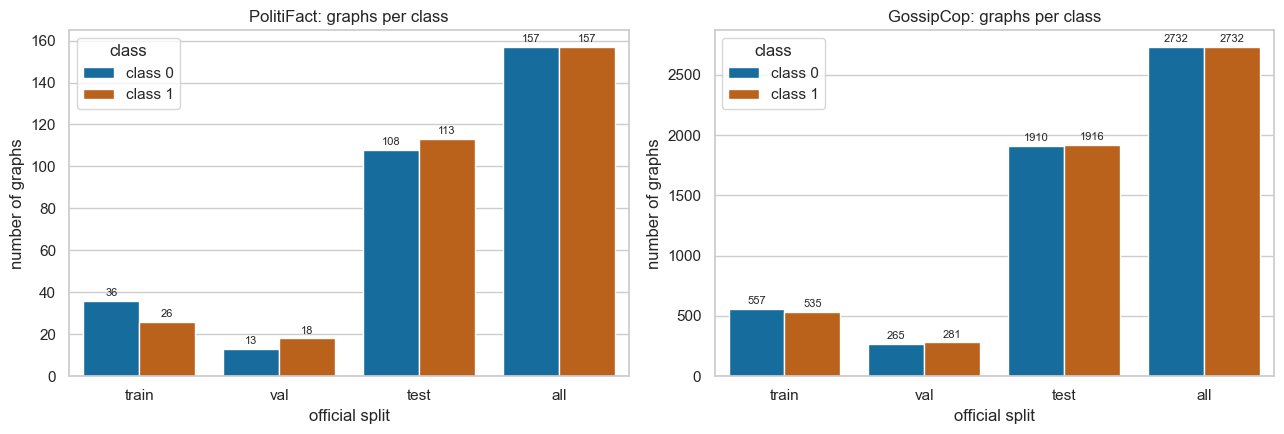

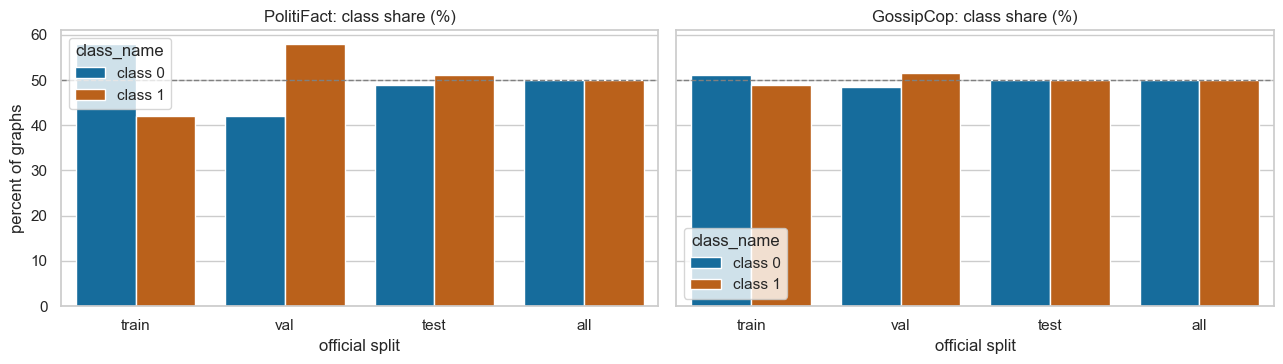

PolitiFact  train: class 0 =  58.1% | class 1 =  41.9%  (imbalance gap 16.1 points)
PolitiFact  val  : class 0 =  41.9% | class 1 =  58.1%  (imbalance gap 16.1 points)
PolitiFact  test : class 0 =  48.9% | class 1 =  51.1%  (imbalance gap 2.3 points)
PolitiFact  all  : class 0 =  50.0% | class 1 =  50.0%  (imbalance gap 0.0 points)
GossipCop   train: class 0 =  51.0% | class 1 =  49.0%  (imbalance gap 2.0 points)
GossipCop   val  : class 0 =  48.5% | class 1 =  51.5%  (imbalance gap 2.9 points)
GossipCop   test : class 0 =  49.9% | class 1 =  50.1%  (imbalance gap 0.2 points)
GossipCop   all  : class 0 =  50.0% | class 1 =  50.0%  (imbalance gap 0.0 points)


In [19]:
rows = []
for name in DATASETS:
    r = RAW[name]
    for split in SPLITS + ["all"]:
        idx = np.arange(r["n_graphs"]) if split == "all" else r["splits"][split]
        counts = np.bincount(r["y"][idx], minlength=2)
        for c in (0, 1):
            rows.append({"dataset": DATASET_TITLES[name], "split": split, "class_index": c,
                         "raw_label": r["classes_raw"][c].item(), "class_name": CLASS_NAMES[c],
                         "count": int(counts[c]), "percent": 100.0 * counts[c] / counts.sum()})
CLASS_DIST = pd.DataFrame(rows)
save_dataframe(CLASS_DIST, METRICS_DIR / "eda_class_distribution.csv")
display(CLASS_DIST.pivot_table(index=["dataset", "split"], columns="class_name", values=["count", "percent"]).round(1))

palette = {CLASS_NAMES[c]: CLASS_COLORS[c] for c in (0, 1)}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, name in zip(axes, DATASETS):
    sub = CLASS_DIST[CLASS_DIST["dataset"] == DATASET_TITLES[name]]
    sns.barplot(data=sub, x="split", y="count", hue="class_name", palette=palette, order=SPLITS + ["all"], ax=ax)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%d", fontsize=8, padding=2)
    ax.set_title(f"{DATASET_TITLES[name]}: graphs per class")
    ax.set_xlabel("official split"); ax.set_ylabel("number of graphs"); ax.legend(title="class")
plt.tight_layout()
save_figure(fig, FIGURES_DIR / "eda" / "class_distribution.png")
plt.show()


fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, name in zip(axes, DATASETS):
    sub = CLASS_DIST[CLASS_DIST["dataset"] == DATASET_TITLES[name]]
    sns.barplot(data=sub, x="split", y="percent", hue="class_name", palette=palette, order=SPLITS + ["all"], ax=ax)
    ax.axhline(50, color="grey", ls="--", lw=1)
    ax.set_title(f"{DATASET_TITLES[name]}: class share (%)"); ax.set_xlabel("official split"); ax.set_ylabel("percent of graphs")
plt.tight_layout()
save_figure(fig, FIGURES_DIR / "eda" / "class_distribution_percent.png")
plt.show()

for name in DATASETS:
    sub = CLASS_DIST[(CLASS_DIST["dataset"] == DATASET_TITLES[name])]
    for split in SPLITS + ["all"]:
        p = sub[sub["split"] == split]["percent"].to_numpy()
        print(f"{DATASET_TITLES[name]:<11} {split:<5}: class 0 = {p[0]:5.1f}% | class 1 = {p[1]:5.1f}%  (imbalance gap {abs(p[0]-p[1]):.1f} points)")

## 8 · Graph structure

In [20]:
GRAPH_STATS = {}
for name in DATASETS:
    t0 = time.perf_counter()
    GRAPH_STATS[name] = compute_all_graph_statistics(RAW[name], desc=f"{DATASET_TITLES[name]} graphs")
    path = save_dataframe(GRAPH_STATS[name], METRICS_DIR / f"{name}_graph_statistics.csv")
    print(f"{DATASET_TITLES[name]:<11}: {len(GRAPH_STATS[name]):,} graphs in {time.perf_counter() - t0:.1f}s -> {path.relative_to(PROJECT_ROOT)}")

STAT_COLS = ["num_nodes", "num_edges", "max_degree", "avg_degree", "degree_std", "root_degree",
             "max_depth", "avg_depth", "leaf_count", "leaf_proportion"]
for name in DATASETS:
    print(f"\n=== {DATASET_TITLES[name]}: distribution of per-graph statistics (all graphs) ===")
    display(GRAPH_STATS[name][STAT_COLS].describe(percentiles=[.05, .25, .5, .75, .95]).round(3))

PolitiFact graphs:   0%|          | 0/314 [00:00<?, ?it/s]

PolitiFact : 314 graphs in 0.8s -> results\metrics\politifact_graph_statistics.csv


GossipCop graphs:   0%|          | 0/5464 [00:00<?, ?it/s]

GossipCop  : 5,464 graphs in 5.5s -> results\metrics\gossipcop_graph_statistics.csv

=== PolitiFact: distribution of per-graph statistics (all graphs) ===


,num_nodes,num_edges,max_degree,avg_degree,degree_std,root_degree,max_depth,avg_depth,leaf_count,leaf_proportion
count,314.000,314.000,314.000,314.000,314.000,314.000,314.000,314.000,314.000,314.000
mean,130.745,129.745,73.755,1.927,5.931,71.041,3.755,1.557,110.105,0.806
std,130.560,130.560,76.952,0.121,3.722,77.481,1.583,0.432,111.577,0.122
min,3.000,2.000,2.000,1.333,0.471,1.000,2.000,1.022,1.000,0.167
5%,6.000,5.000,4.000,1.667,1.013,2.000,2.000,1.067,4.000,0.534
25%,26.000,25.000,16.250,1.923,3.138,15.000,2.000,1.227,21.000,0.770
50%,78.500,77.500,44.000,1.975,5.249,40.000,3.000,1.469,65.500,0.829
75%,216.750,215.750,115.250,1.991,8.283,110.500,5.000,1.770,181.750,0.878
95%,415.700,414.700,230.700,1.995,13.132,230.700,6.000,2.336,342.400,0.949
max,497.000,496.000,450.000,1.996,20.119,450.000,12.000,3.891,459.000,0.978



=== GossipCop: distribution of per-graph statistics (all graphs) ===


,num_nodes,num_edges,max_degree,avg_degree,degree_std,root_degree,max_depth,avg_depth,leaf_count,leaf_proportion
count,5464.000,5464.000,5464.000,5464.000,5464.000,5464.000,5464.000,5464.000,5464.000,5464.000
mean,57.515,56.515,44.423,1.914,5.330,43.342,2.512,1.251,52.941,0.871
std,45.231,45.231,34.811,0.102,2.754,34.698,0.950,0.277,42.943,0.116
min,3.000,2.000,2.000,1.333,0.471,1.000,2.000,1.005,1.000,0.250
5%,7.000,6.000,4.000,1.714,1.161,4.000,2.000,1.015,5.000,0.636
25%,19.000,18.000,14.000,1.895,2.962,13.000,2.000,1.056,16.000,0.818
50%,49.000,48.000,38.000,1.959,5.396,36.000,2.000,1.162,45.000,0.912
75%,84.000,83.000,67.000,1.976,7.467,66.000,3.000,1.349,79.000,0.957
95%,150.000,149.000,110.000,1.987,9.813,110.000,5.000,1.785,141.000,0.976
max,199.000,198.000,187.000,1.990,13.493,187.000,9.000,3.909,193.000,0.989


### 8.1 Connected graphs and trees

In [21]:
rows = []
for name in DATASETS:
    df = GRAPH_STATS[name]
    rows.append({
        "dataset": DATASET_TITLES[name], "graphs": len(df),
        "connected from node 0": f"{int(df.is_connected.sum())} / {len(df)}",
        "tree (connected, undirected edges = n-1)": f"{int(df.is_tree.sum())} / {len(df)}",
        "num_edges == num_nodes - 1": f"{int((df.num_edges == df.num_nodes - 1).sum())} / {len(df)}",
        "avg_degree == 2(n-1)/n (numerically)": bool(np.allclose(df.avg_degree, 2 * (df.num_nodes - 1) / df.num_nodes)),
        "graphs with a single node": int((df.num_nodes == 1).sum()),
    })
TREE_CHECK = pd.DataFrame(rows).set_index("dataset")
display(TREE_CHECK.T)
print("If 'num_edges == num_nodes - 1' holds for every graph, num_edges and avg_degree carry no information beyond "
      "num_nodes and are dropped from the Random Forest baseline (decided on the TRAINING split only in notebook 02).")

dataset,PolitiFact,GossipCop
graphs,314,5464
connected from node 0,314 / 314,5464 / 5464
"tree (connected, undirected edges = n-1)",314 / 314,5464 / 5464
num_edges == num_nodes - 1,314 / 314,5464 / 5464
avg_degree == 2(n-1)/n (numerically),True,True
graphs with a single node,0,0


If 'num_edges == num_nodes - 1' holds for every graph, num_edges and avg_degree carry no information beyond num_nodes and are dropped from the Random Forest baseline (decided on the TRAINING split only in notebook 02).


### 8.2 Size distributions and correlations

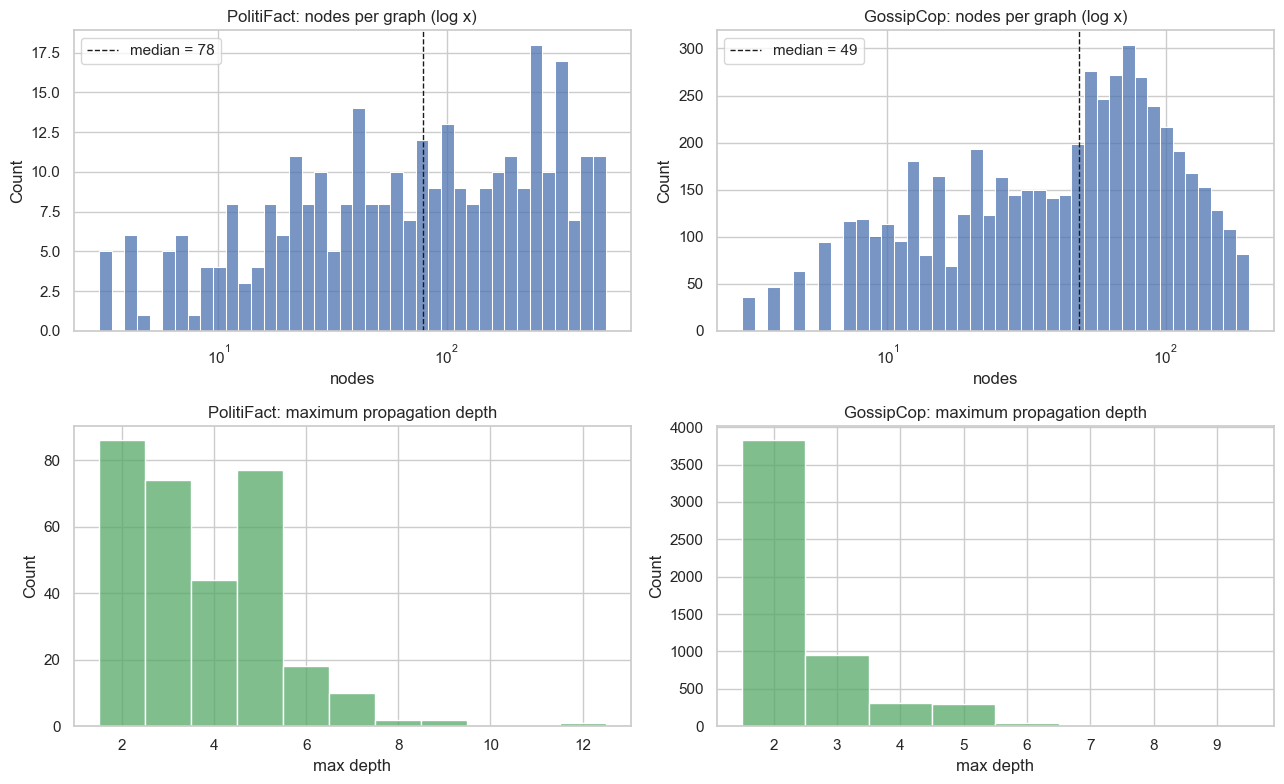

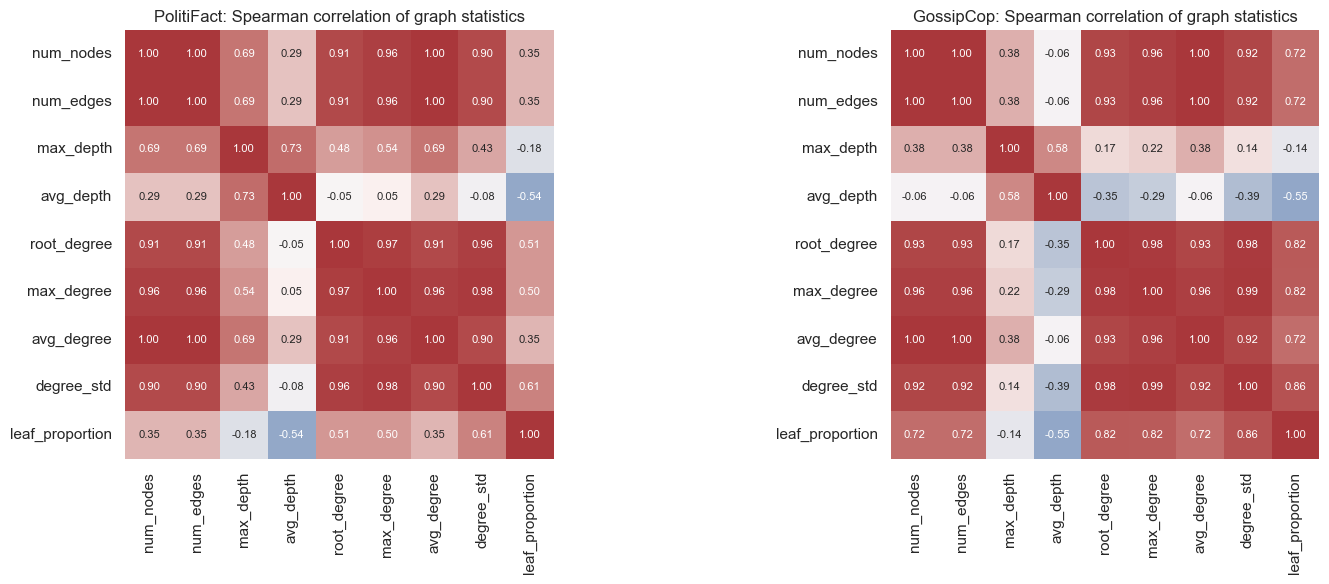

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for j, name in enumerate(DATASETS):
    df = GRAPH_STATS[name]
    sns.histplot(df["num_nodes"], bins=40, log_scale=True, ax=axes[0, j], color="#4C72B0")
    axes[0, j].axvline(df["num_nodes"].median(), color="k", ls="--", lw=1, label=f"median = {df['num_nodes'].median():.0f}")
    axes[0, j].set_title(f"{DATASET_TITLES[name]}: nodes per graph (log x)"); axes[0, j].set_xlabel("nodes"); axes[0, j].legend()
    sns.histplot(df["max_depth"], discrete=True, ax=axes[1, j], color="#55A868")
    axes[1, j].set_title(f"{DATASET_TITLES[name]}: maximum propagation depth"); axes[1, j].set_xlabel("max depth")
plt.tight_layout()
save_figure(fig, FIGURES_DIR / "eda" / "graph_size_and_depth_distributions.png")
plt.show()

corr_cols = ["num_nodes", "num_edges", "max_depth", "avg_depth", "root_degree", "max_degree", "avg_degree", "degree_std", "leaf_proportion"]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, name in zip(axes, DATASETS):
    c = GRAPH_STATS[name][corr_cols].corr(method="spearman")
    sns.heatmap(c, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, square=True, cbar=False, ax=ax, annot_kws={"fontsize": 8})
    ax.set_title(f"{DATASET_TITLES[name]}: Spearman correlation of graph statistics")
plt.tight_layout()
save_figure(fig, FIGURES_DIR / "eda" / "graph_statistics_correlation.png")
plt.show()

### 8.3 How graphs are processed

- Nodes of all graphs are stored in one long matrix. `node_slice[i]` to `node_slice[i+1]` gives the rows of graph `i`.
- Edges in `A.txt` use global node ids. They are grouped by graph (`edge_slice`) and the first node id of the graph is subtracted, so every graph has local ids and its root is node 0.
- A GNN mini-batch joins several graphs into one large disconnected graph, shifting node ids. The `batch` vector says which graph each node belongs to.

In [23]:
for name in DATASETS:
    r = RAW[name]
    for i in (0, 1):
        print(f"{DATASET_TITLES[name]} graph {i}: node rows {r['node_slice'][i]}-{r['node_slice'][i + 1]}, "
              f"edge rows {r['edge_slice'][i]}-{r['edge_slice'][i + 1]}, first local edges {local_edges(r, i)[:3].tolist()}")

PolitiFact graph 0: node rows 0-497, edge rows 0-496, first local edges [[0, 1], [0, 2], [0, 3]]
PolitiFact graph 1: node rows 497-518, edge rows 496-516, first local edges [[0, 1], [0, 2], [0, 3]]
GossipCop graph 0: node rows 0-57, edge rows 0-56, first local edges [[0, 1], [0, 2], [0, 3]]
GossipCop graph 1: node rows 57-111, edge rows 56-109, first local edges [[0, 1], [0, 2], [0, 3]]


## 9 · Class comparison

In [24]:
COMPARE_COLS = ["num_nodes", "num_edges", "max_degree", "avg_degree", "max_depth", "avg_depth", "root_degree", "leaf_proportion"]
COUNT_LIKE = {"num_nodes", "num_edges", "max_degree", "max_depth", "root_degree"}

rows = []
for name in DATASETS:
    df = GRAPH_STATS[name]
    for col in COMPARE_COLS:
        a = df.loc[df.label == 0, col].to_numpy(float)
        b = df.loc[df.label == 1, col].to_numpy(float)
        try:
            U, p = scistats.mannwhitneyu(a, b, alternative="two-sided")
            ps = U / (len(a) * len(b))
        except ValueError:
            U, p, ps = np.nan, np.nan, np.nan
        rows.append({"dataset": DATASET_TITLES[name], "statistic": col,
                     "median_class0": np.median(a), "median_class1": np.median(b),
                     "mean_class0": a.mean(), "mean_class1": b.mean(),
                     "std_class0": a.std(ddof=1), "std_class1": b.std(ddof=1),
                     "mannwhitney_p": p, "prob_superiority_class0_gt_class1": ps})
CLASS_COMPARE = pd.DataFrame(rows)
CLASS_COMPARE["bonferroni_threshold"] = 0.05 / len(COMPARE_COLS)
CLASS_COMPARE["significant_after_bonferroni"] = CLASS_COMPARE["mannwhitney_p"] < CLASS_COMPARE["bonferroni_threshold"]
save_dataframe(CLASS_COMPARE, METRICS_DIR / "eda_class_comparison.csv")
display(CLASS_COMPARE.round(4))

,dataset,statistic,median_class0,median_class1,mean_class0,mean_class1,std_class0,std_class1,mannwhitney_p,prob_superiority_class0_gt_class1,bonferroni_threshold,significant_after_bonferroni
0,PolitiFact,num_nodes,58.0000,104.0000,114.9172,146.5732,129.4658,130.1355,0.0048,0.4080,0.0062,True
1,PolitiFact,num_edges,57.0000,103.0000,113.9172,145.5732,129.4658,130.1355,0.0048,0.4080,0.0062,True
2,PolitiFact,max_degree,37.0000,58.0000,66.4076,81.1019,80.6767,72.5519,0.0065,0.4113,0.0062,False
3,PolitiFact,avg_degree,1.9655,1.9808,1.9086,1.9452,0.1382,0.0977,0.0048,0.4080,0.0062,True
4,PolitiFact,max_depth,3.0000,4.0000,3.6242,3.8854,1.6346,1.5232,0.0743,0.4432,0.0062,False
5,PolitiFact,avg_depth,1.4375,1.4770,1.5534,1.5612,0.4771,0.3823,0.2847,0.4651,0.0062,False
6,PolitiFact,root_degree,30.0000,54.0000,62.6752,79.4076,80.5565,73.5862,0.0044,0.4071,0.0062,True
7,PolitiFact,leaf_proportion,0.8305,0.8283,0.7946,0.8183,0.1445,0.0942,0.6917,0.4870,0.0062,False
8,GossipCop,num_nodes,70.0000,22.0000,76.1636,38.8664,40.6279,41.7849,0.0000,0.7891,0.0062,True
9,GossipCop,num_edges,69.0000,21.0000,75.1636,37.8664,40.6279,41.7849,0.0000,0.7891,0.0062,True


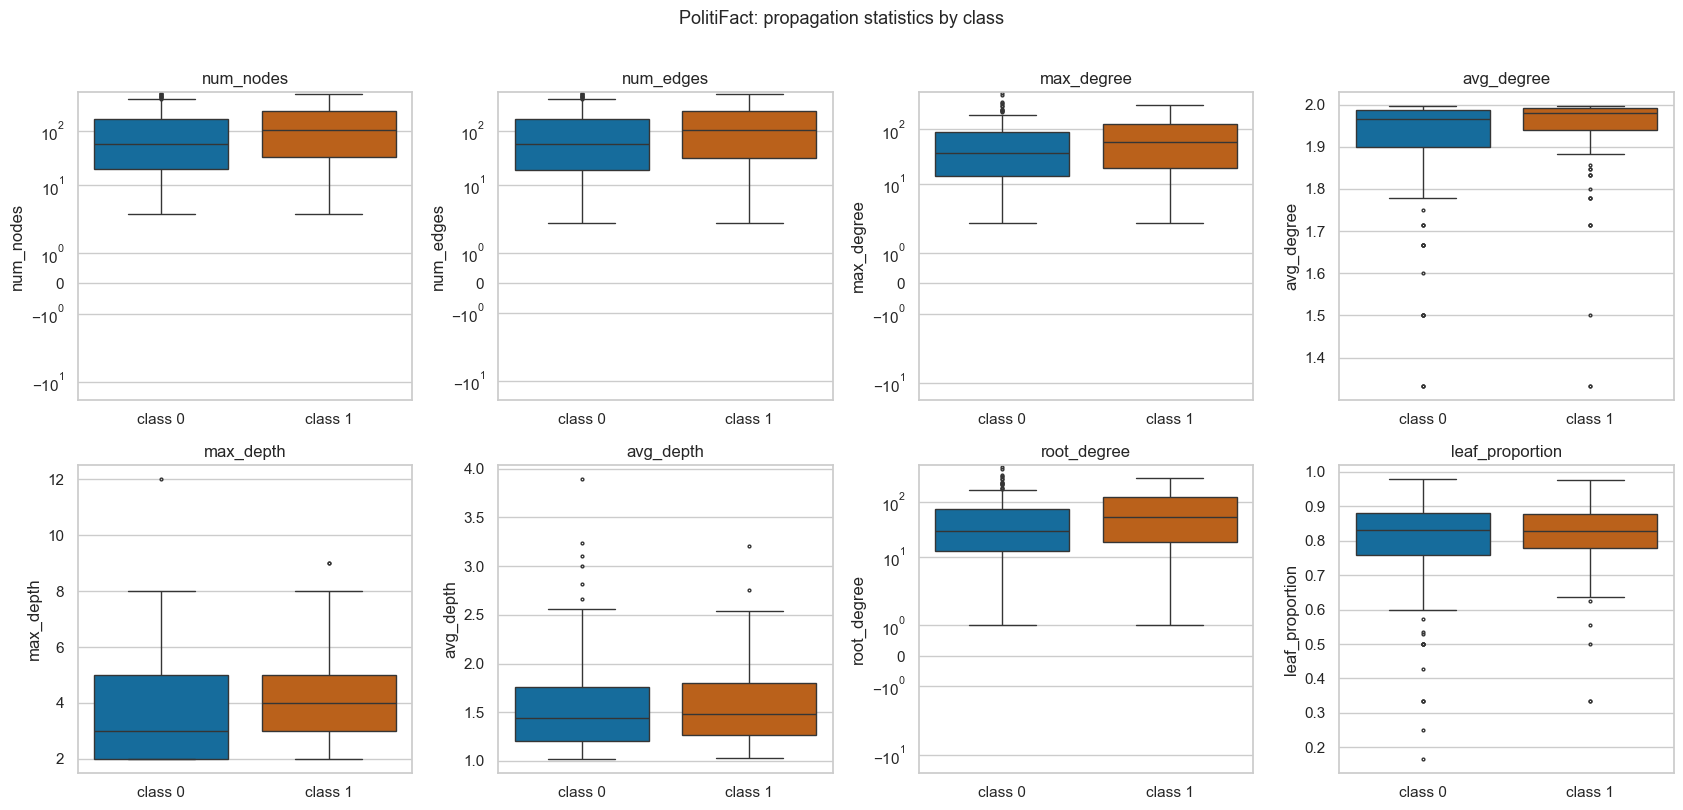

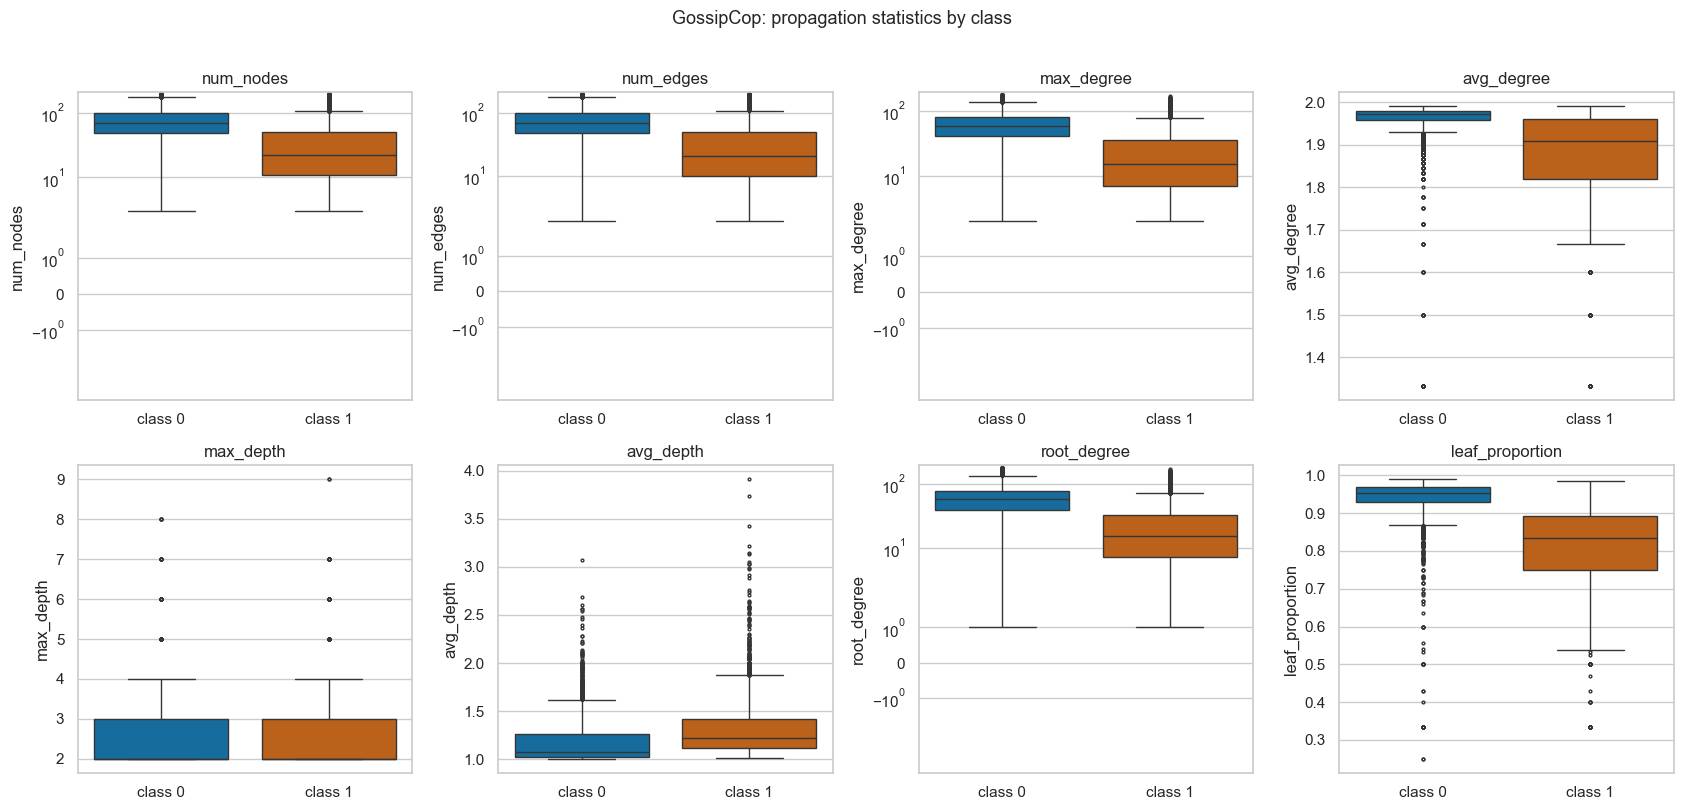

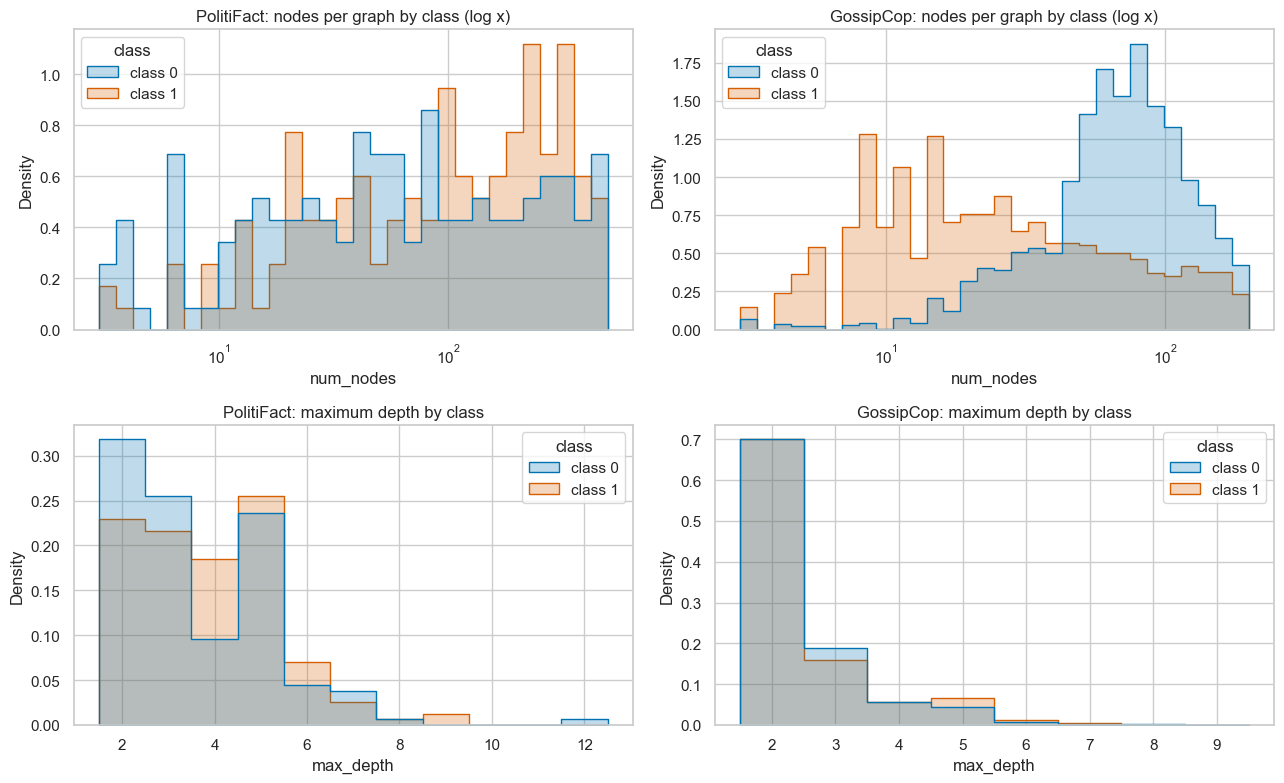

In [25]:
palette = {CLASS_NAMES[c]: CLASS_COLORS[c] for c in (0, 1)}
for name in DATASETS:
    df = GRAPH_STATS[name].copy()
    df["class"] = df["label"].map(CLASS_NAMES)
    fig, axes = plt.subplots(2, 4, figsize=(17, 8))
    for ax, col in zip(axes.ravel(), COMPARE_COLS):
        sns.boxplot(data=df, x="class", y=col, hue="class", palette=palette, order=[CLASS_NAMES[0], CLASS_NAMES[1]],
                    legend=False, ax=ax, fliersize=2)
        if col in COUNT_LIKE and col != "max_depth":
            ax.set_yscale("symlog")
        ax.set_title(col); ax.set_xlabel("")
    fig.suptitle(f"{DATASET_TITLES[name]}: propagation statistics by class", y=1.01, fontsize=13)
    plt.tight_layout()
    save_figure(fig, FIGURES_DIR / "eda" / f"{name}_boxplots_by_class.png")
    plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for j, name in enumerate(DATASETS):
    df = GRAPH_STATS[name].copy()
    df["class"] = df["label"].map(CLASS_NAMES)
    sns.histplot(data=df, x="num_nodes", hue="class", palette=palette, log_scale=True, element="step",
                 stat="density", common_norm=False, bins=30, ax=axes[0, j])
    axes[0, j].set_title(f"{DATASET_TITLES[name]}: nodes per graph by class (log x)")
    sns.histplot(data=df, x="max_depth", hue="class", palette=palette, discrete=True, element="step",
                 stat="density", common_norm=False, ax=axes[1, j])
    axes[1, j].set_title(f"{DATASET_TITLES[name]}: maximum depth by class")
plt.tight_layout()
save_figure(fig, FIGURES_DIR / "eda" / "size_and_depth_by_class.png")
plt.show()

## 10 · BERT features

In [26]:
def scan_features(X, chunk=20000):
    n, d = X.shape
    norms = np.empty(n, dtype=np.float32)
    n_nan = n_inf = n_zero = 0
    vmin, vmax = np.inf, -np.inf
    s1, s2 = np.zeros(d), np.zeros(d)
    for a in tqdm(range(0, n, chunk), desc="scanning features", leave=False):
        block = X[a:a + chunk].toarray()
        n_nan += int(np.isnan(block).sum())
        n_inf += int(np.isinf(block).sum())
        bad = ~np.isfinite(block)
        if bad.any():
            block = np.where(bad, 0.0, block)
        norms[a:a + chunk] = np.linalg.norm(block, axis=1)
        n_zero += int((block == 0).sum())
        vmin, vmax = min(vmin, float(block.min())), max(vmax, float(block.max()))
        s1 += block.sum(axis=0, dtype=np.float64)
        s2 += np.square(block, dtype=np.float64).sum(axis=0)
    mean = s1 / n
    var = np.maximum(s2 / n - mean ** 2, 0)
    return {"norms": norms, "n_nan": n_nan, "n_inf": n_inf, "frac_zero": n_zero / (n * d), "min": vmin, "max": vmax,
            "global_mean": float(mean.mean()), "global_std": float(np.sqrt(var).mean()), "dim_mean": mean, "dim_std": np.sqrt(var)}


FEAT = {}
rows = []
for name in DATASETS:
    r = RAW[name]
    FEAT[name] = scan_features(r["X"])
    f = FEAT[name]
    is_root = np.zeros(r["n_nodes"], dtype=bool)
    is_root[r["node_slice"][:-1]] = True
    f["is_root"] = is_root
    rows.append({"dataset": DATASET_TITLES[name], "dtype (as stored)": str(r["X"].dtype), "shape": r["X"].shape,
                 "NaN values": f["n_nan"], "Inf values": f["n_inf"], "min value": f["min"], "max value": f["max"],
                 "mean of per-dim means": f["global_mean"], "mean of per-dim stds": f["global_std"],
                 "fraction of exactly-zero entries": f["frac_zero"],
                 "L2 norm: mean (all nodes)": float(f["norms"].mean()),
                 "L2 norm: mean (root nodes)": float(f["norms"][is_root].mean()),
                 "L2 norm: mean (user nodes)": float(f["norms"][~is_root].mean()),
                 "all-zero rows": int((f["norms"] == 0).sum())})
display(pd.DataFrame(rows).set_index("dataset").T)

scanning features:   0%|          | 0/3 [00:00<?, ?it/s]

scanning features:   0%|          | 0/16 [00:00<?, ?it/s]

dataset,PolitiFact,GossipCop
dtype (as stored),float32,float32
shape,"(41054, 768)","(314262, 768)"
NaN values,0,0
Inf values,0,0
min value,-25.066866,-26.82576
max value,1.871673,2.466124
mean of per-dim means,-0.028827,-0.029245
mean of per-dim stds,0.090321,0.112837
fraction of exactly-zero entries,0.0,0.0
L2 norm: mean (all nodes),23.748058,24.006063


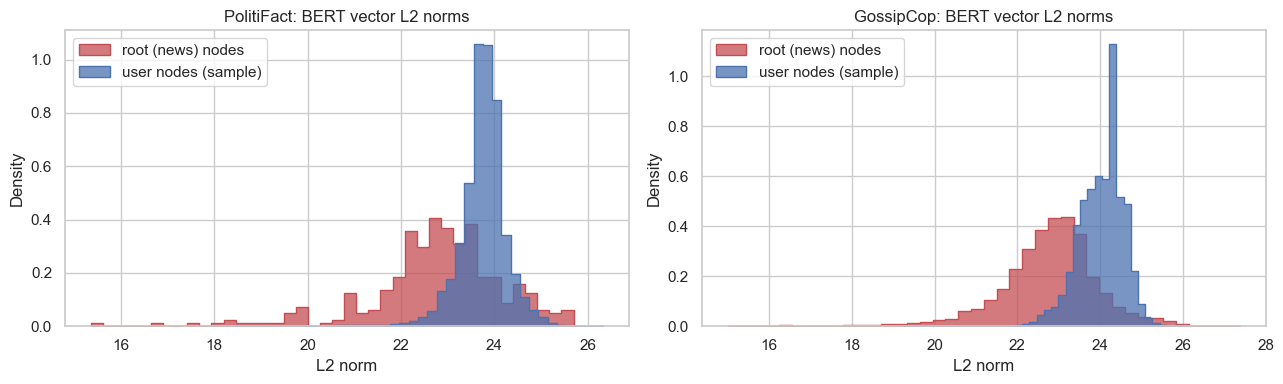

PolitiFact : 290 distinct root vectors among 314 graphs
GossipCop  : 5145 distinct root vectors among 5464 graphs


In [27]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, name in zip(axes, DATASETS):
    f = FEAT[name]
    users = f["norms"][~f["is_root"]]
    users = rng.choice(users, size=min(len(users), 50000), replace=False)
    sns.histplot(f["norms"][f["is_root"]], stat="density", bins=40, color="#C44E52", label="root (news) nodes", ax=ax, element="step")
    sns.histplot(users, stat="density", bins=40, color="#4C72B0", label="user nodes (sample)", ax=ax, element="step")
    ax.set_title(f"{DATASET_TITLES[name]}: BERT vector L2 norms"); ax.set_xlabel("L2 norm"); ax.legend()
plt.tight_layout()
save_figure(fig, FIGURES_DIR / "eda" / "bert_norm_distributions.png")
plt.show()


for name in DATASETS:
    r = RAW[name]
    roots = root_features(r, np.arange(r["n_graphs"]))
    n_unique = np.unique(np.round(roots, 6), axis=0).shape[0]
    print(f"{DATASET_TITLES[name]:<11}: {n_unique} distinct root vectors among {r['n_graphs']} graphs")

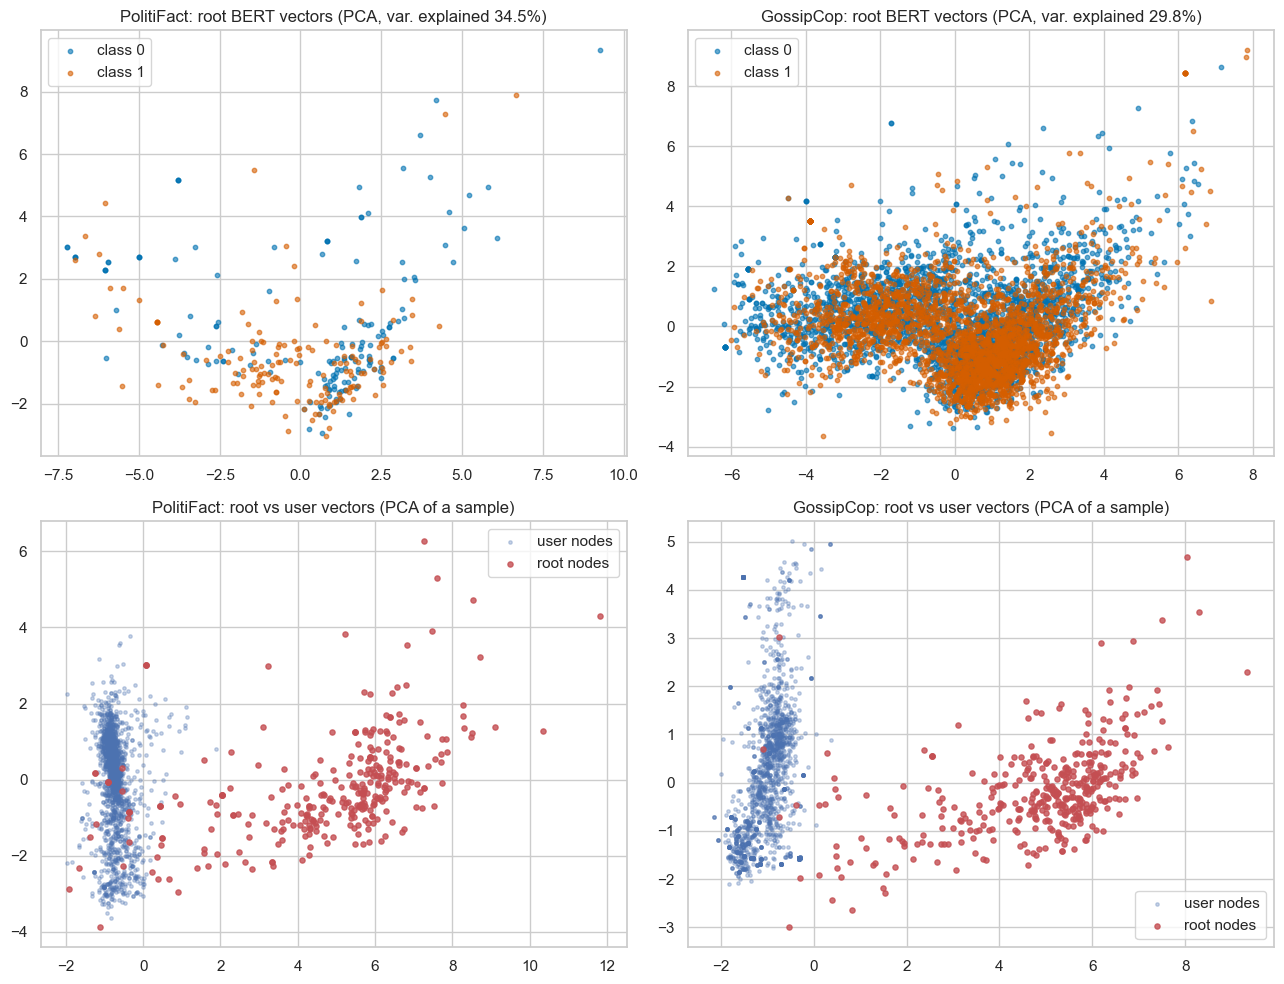

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for j, name in enumerate(DATASETS):
    r = RAW[name]
    roots = root_features(r, np.arange(r["n_graphs"]))
    pca = PCA(n_components=2, random_state=SEED).fit(roots)
    z = pca.transform(roots)
    for c in (0, 1):
        m = r["y"] == c
        axes[0, j].scatter(z[m, 0], z[m, 1], s=10, alpha=0.6, color=CLASS_COLORS[c], label=CLASS_NAMES[c])
    axes[0, j].set_title(f"{DATASET_TITLES[name]}: root BERT vectors (PCA, var. explained {pca.explained_variance_ratio_.sum():.1%})")
    axes[0, j].legend()

    n_roots = min(400, r["n_graphs"])
    root_rows = r["node_slice"][:-1][rng.choice(r["n_graphs"], size=n_roots, replace=False)]
    user_pool = np.flatnonzero(~FEAT[name]["is_root"])
    user_rows = rng.choice(user_pool, size=min(2000, len(user_pool)), replace=False)
    pooled = r["X"][np.concatenate([root_rows, user_rows])].toarray()
    zz = PCA(n_components=2, random_state=SEED).fit_transform(pooled)
    axes[1, j].scatter(zz[n_roots:, 0], zz[n_roots:, 1], s=6, alpha=0.3, color="#4C72B0", label="user nodes")
    axes[1, j].scatter(zz[:n_roots, 0], zz[:n_roots, 1], s=14, alpha=0.8, color="#C44E52", label="root nodes")
    axes[1, j].set_title(f"{DATASET_TITLES[name]}: root vs user vectors (PCA of a sample)")
    axes[1, j].legend()
plt.tight_layout()
save_figure(fig, FIGURES_DIR / "eda" / "bert_pca_root_and_user.png")
plt.show()

## 11 · Sample graphs

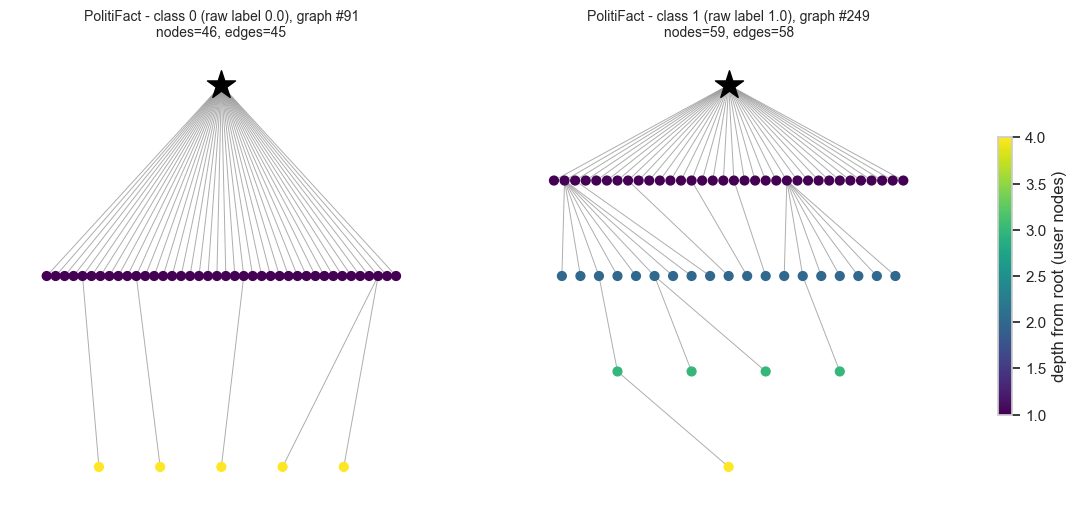

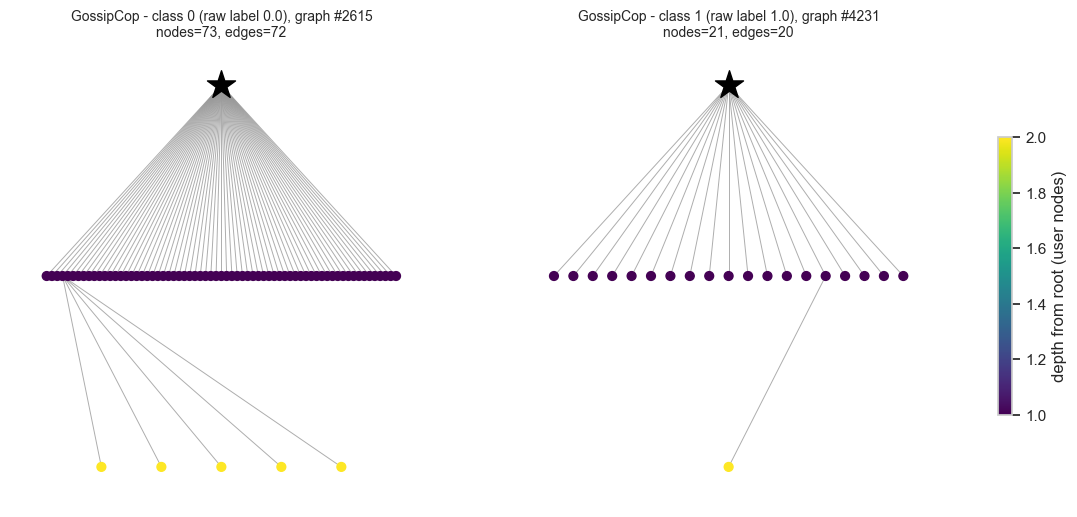

In [29]:
def reduce_tree_for_display(n_nodes, edges, max_nodes=120, seed=SEED):
    G = nx.Graph()
    G.add_nodes_from(range(n_nodes))
    G.add_edges_from((int(a), int(b)) for a, b in edges if a != b)
    depth = nx.single_source_shortest_path_length(G, 0)
    if n_nodes <= max_nodes:
        return G, depth, False
    rng_local = np.random.default_rng(seed)
    layers = {}
    for v, dep in depth.items():
        layers.setdefault(dep, []).append(v)
    keep = {0}
    for dep in sorted(layers):
        if dep == 0:
            continue
        room = max_nodes - len(keep)
        if room <= 0:
            break
        nodes = layers[dep]
        if len(nodes) <= room:
            keep.update(nodes)
        else:
            keep.update(rng_local.choice(nodes, size=room, replace=False).tolist())
            break
    return G.subgraph(keep).copy(), depth, True


def layered_layout(H, depth):
    levels = {}
    for v in H.nodes:
        levels.setdefault(depth[v], []).append(v)
    pos = {}
    for dep, nodes in levels.items():
        nodes = sorted(nodes)
        xs = np.linspace(0, 1, len(nodes) + 2)[1:-1] if len(nodes) > 1 else [0.5]
        for x, v in zip(xs, nodes):
            pos[v] = (x, -dep)
    return pos


def draw_graph(ax, raw, gi, title):
    H, depth, reduced = reduce_tree_for_display(graph_num_nodes(raw, gi), local_edges(raw, gi))
    pos = layered_layout(H, depth)
    users = [v for v in H.nodes if v != 0]
    nx.draw_networkx_edges(H, pos, ax=ax, edge_color="#999999", width=0.7, alpha=0.8)
    nodes = nx.draw_networkx_nodes(H, pos, nodelist=users, node_size=40, node_color=[depth[v] for v in users],
                                   cmap="viridis", ax=ax)
    nx.draw_networkx_nodes(H, pos, nodelist=[0], node_size=450, node_color="black", node_shape="*", ax=ax)
    note = f" (display reduced to {H.number_of_nodes()} of {graph_num_nodes(raw, gi)} nodes)" if reduced else ""
    ax.set_title(f"{title}\nnodes={graph_num_nodes(raw, gi)}, edges={len(local_edges(raw, gi))}{note}", fontsize=10)
    ax.axis("off")
    return nodes


for name in DATASETS:
    r, df = RAW[name], GRAPH_STATS[name]
    train_df = df[df["split"] == "train"]
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for c, ax in zip((0, 1), axes):
        cls = train_df[train_df["label"] == c]
        target = cls["num_nodes"].median()
        gi = int(cls.iloc[(cls["num_nodes"] - target).abs().argsort().iloc[0]]["graph_idx"])
        sc = draw_graph(ax, r, gi, f"{DATASET_TITLES[name]} - {CLASS_NAMES[c]} (raw label {r['classes_raw'][c].item()}), graph #{gi}")
    fig.colorbar(sc, ax=axes, shrink=0.6, label="depth from root (user nodes)")
    save_figure(fig, FIGURES_DIR / "eda" / f"{name}_sample_graphs.png")
    plt.show()

## 12 · Conclusions

In [30]:
lines = []
S = SUMMARY.set_index("dataset")
for name in DATASETS:
    t, s = DATASET_TITLES[name], S.loc[name]
    lines.append(f"[{t}] {s.total_graphs:,} graphs ({s.train_graphs} train / {s.val_graphs} val / {s.test_graphs} test), "
                 f"{s.total_nodes:,} nodes, {s.total_edges_coalesced:,} edges; mean {s.avg_nodes_per_graph} and median "
                 f"{s.median_nodes_per_graph:g} nodes per graph (max {s.max_graph_size_nodes}).")
lines.append(f"Dataset size: GossipCop has {S.loc['gossipcop'].total_graphs / S.loc['politifact'].total_graphs:.1f}x as many graphs as PolitiFact, "
             f"but its graphs are {'smaller' if S.loc['gossipcop'].avg_nodes_per_graph < S.loc['politifact'].avg_nodes_per_graph else 'larger'} on average "
             f"({S.loc['gossipcop'].avg_nodes_per_graph} vs {S.loc['politifact'].avg_nodes_per_graph} nodes).")
for name in DATASETS:
    sub = CLASS_DIST[(CLASS_DIST.dataset == DATASET_TITLES[name]) & (CLASS_DIST.split == "all")]
    sp_ = CLASS_DIST[(CLASS_DIST.dataset == DATASET_TITLES[name]) & (CLASS_DIST.split != "all")].groupby("split")["percent"].apply(lambda s: s.max())
    lines.append(f"[{DATASET_TITLES[name]}] class balance overall: {sub.percent.iloc[0]:.1f}% / {sub.percent.iloc[1]:.1f}% (class 0 / class 1); "
                 f"largest class share per split: " + ", ".join(f"{k} {v:.1f}%" for k, v in sp_.items()) + ".")
for name in DATASETS:
    t = TREE_CHECK.loc[DATASET_TITLES[name]]
    lines.append(f"[{DATASET_TITLES[name]}] structure: tree graphs = {t['tree (connected, undirected edges = n-1)']}; "
                 f"edges == nodes-1 in {t['num_edges == num_nodes - 1']} graphs.")
for name in DATASETS:
    sub = CLASS_COMPARE[(CLASS_COMPARE.dataset == DATASET_TITLES[name])]
    sig = sub[sub.significant_after_bonferroni]
    if len(sig):
        desc = "; ".join(f"{r.statistic}: median {r.median_class0:g} (class 0) vs {r.median_class1:g} (class 1), p={r.mannwhitney_p:.2g}" for r in sig.itertuples())
        lines.append(f"[{DATASET_TITLES[name]}] class differences surviving Bonferroni correction: {desc}.")
    else:
        lines.append(f"[{DATASET_TITLES[name]}] no propagation statistic differs between the classes after Bonferroni correction "
                     f"(smallest p = {sub.mannwhitney_p.min():.3g}).")
for name in DATASETS:
    f = FEAT[name]
    lines.append(f"[{DATASET_TITLES[name]}] BERT features: dim {RAW[name]['X'].shape[1]}, NaN={f['n_nan']}, Inf={f['n_inf']}, "
                 f"mean L2 norm root {f['norms'][f['is_root']].mean():.2f} vs user {f['norms'][~f['is_root']].mean():.2f}; "
                 f"{int((f['norms'] == 0).sum())} all-zero vectors.")
lines.append("Label semantics (fake vs real): " + ("UNVERIFIED - classes reported as class 0 / class 1." if FAKE_CLASS_INDEX is None
             else f"user-confirmed: class {FAKE_CLASS_INDEX} = fake."))
print("\n".join("- " + l for l in lines))

- [PolitiFact] 314.0 graphs (62.0 train / 31.0 val / 221.0 test), 41,054.0 nodes, 40,740.0 edges; mean 130.75 and median 78.5 nodes per graph (max 497.0).
- [GossipCop] 5,464.0 graphs (1092.0 train / 546.0 val / 3826.0 test), 314,262.0 nodes, 308,798.0 edges; mean 57.52 and median 49 nodes per graph (max 199.0).
- Dataset size: GossipCop has 17.4x as many graphs as PolitiFact, but its graphs are smaller on average (57.52 vs 130.75 nodes).
- [PolitiFact] class balance overall: 50.0% / 50.0% (class 0 / class 1); largest class share per split: test 51.1%, train 58.1%, val 58.1%.
- [GossipCop] class balance overall: 50.0% / 50.0% (class 0 / class 1); largest class share per split: test 50.1%, train 51.0%, val 51.5%.
- [PolitiFact] structure: tree graphs = 314 / 314; edges == nodes-1 in 314 / 314 graphs.
- [GossipCop] structure: tree graphs = 5464 / 5464; edges == nodes-1 in 5464 / 5464 graphs.
- [PolitiFact] class differences surviving Bonferroni correction: num_nodes: median 58 (class 0) 

Limitations: UPFD is a processed subset of FakeNewsNet, user vectors summarise historical posts rather than comments on the news item, and the fake/real label meaning is unverified.

## 13 · Saved files

In [31]:
inventory = pd.DataFrame(SAVED_ARTIFACTS)
display(inventory)
required_outputs = [METRICS_DIR / "dataset_summary.csv",
                    METRICS_DIR / "politifact_graph_statistics.csv",
                    METRICS_DIR / "gossipcop_graph_statistics.csv"]
for p in required_outputs:
    print(("OK       " if p.is_file() else "MISSING  ") + str(p.relative_to(PROJECT_ROOT)))
print(f"\nTotal files written by this notebook: {len(inventory)}")

,kind,path,size_kB
0,csv,results\metrics\dataset_summary.csv,0.5
1,csv,results\metrics\computational_summary.csv,0.2
2,csv,results\metrics\eda_class_distribution.csv,0.8
3,figure,results\figures\eda\class_distribution.png,58.4
4,figure,results\figures\eda\class_distribution_percent...,51.7
5,csv,results\metrics\politifact_graph_statistics.csv,34.8
6,csv,results\metrics\gossipcop_graph_statistics.csv,594.2
7,figure,results\figures\eda\graph_size_and_depth_distr...,95.3
8,figure,results\figures\eda\graph_statistics_correlati...,157.3
9,csv,results\metrics\eda_class_comparison.csv,2.8


OK       results\metrics\dataset_summary.csv
OK       results\metrics\politifact_graph_statistics.csv
OK       results\metrics\gossipcop_graph_statistics.csv

Total files written by this notebook: 17
